In [52]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from matplotlib.font_manager import FontProperties
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import matplotlib.pyplot as plt
import scipy as sp
from scipy.odr import *
import random
import operator
import os

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
from statsmodels.formula.api import wls
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

In [53]:
#plt.rcParams['figure.facecolor'] = 'w'
#plt.rcParams['figure.edgecolor'] = 'k'

In [54]:
M0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundMStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip
M1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneMStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundamentalCStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneCStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip

MdotIndex=5 # Column of imported files that has Mdot data
MdotErrorIndex=6 # Absolute error in Mdot
#MdotIndex=2 # Column of imported files that has Mdot_dust Data
LIndex=8 # Column of imported files that has LBol data
LErrorIndex=9 # Absolute error in L
PIndex=13 # Column of imported files that has Period data
JIndex=14 # Column of imported files that has J-band magnitude
KIndex=16 # Column of imported files that has J-band magnitude
ThreePointSixIndex=17 # Column of imported files that has 3.6 band magnitude
EightPointZeroIndex=20 # Column of imported files that has 8.0 band magnitude
MIndex=22 # Column of imported files that has Mass data
RIndex=23 # Column of imported files that has Radius data
TeffObsvIndex=12 # Column of imported files that has Observed Teff Data
TeffCalcIndex=24 # Column of imported files that has Calculated Teff Data
tauIndex=27 # Column of imported files that has Optical Depth data

In [55]:
def clear_rows_with_nAn_for_color (RawStarData, band_1_index, band_2_index ):
    band_1_nAn_index = []
    band_2_nAn_index = []
    band_1_data = RawStarData[band_1_index]
    band_2_data = RawStarData[band_2_index]
    band_1_nAn = np.isnan(band_1_data)
    band_2_nAn = np.isnan(band_2_data)
    index_list_1 = np.where(band_1_nAn == True)[0]
    index_list_2 = np.where(band_2_nAn == True)[0]
    full_index_list = np.concatenate((index_list_1, index_list_2))
    full_index_list = np.unique(full_index_list) # Note: This function also *sorts* the array
    working_data = np.transpose(RawStarData)
    reduced_data = np.delete(working_data, full_index_list, 0)
    print('Stars removed (nAn):', len(np.transpose(RawStarData))-len(reduced_data))
    return np.transpose(reduced_data)
def clear_rows_with_color_less_than_value (RawStarData, band_1_index, band_2_index,value=0 ):
    band_1_data = RawStarData[band_1_index]
    band_2_data = RawStarData[band_2_index]
    color = band_1_data - band_2_data
    less_than_value = []
    for i in range (0,len(color)):
        if color[i] < value:
            less_than_value.append(i)
    #print(less_than_value)
    full_index_list = np.unique(less_than_value) # Note: This function also *sorts* the array
    working_data = np.transpose(RawStarData)
    reduced_data = np.delete(working_data, full_index_list, 0)
    print('Stars removed (color<'+str(value)+'):', len(np.transpose(RawStarData))-len(reduced_data))
    return np.transpose(reduced_data)
def calculate_color (band_1, band_2):
    return band_1 - band_2

In [56]:
def sort_xC0(stellar_data): # Function to separate 'extreme' AGB stars from the carbon star population
    '''
    “As in Blum et al. (2006) and Srinivasan et al. (2009), we identify x-AGB stars as those brighter than the 3.6 μm TRGB and 
    with J −[3.6] > 3.1 mag. Some of the most heavily dust-enshrouded x-AGB stars are totally undetected in the near-IR. 
    Therefore, if there is no near-IR detection, but [3.6] − [8] > 0.8 and the star is brighter than the 3.6 μm TRGB, then it is
    also included in the initial list of x-AGB stars.” 
    - Boyer et. al, 2011 https://iopscience.iop.org/article/10.1088/0004-6256/142/4/103/pdf
    '''
    mag_J = stellar_data[JIndex]
    mag_36 = stellar_data[ThreePointSixIndex]
    mag_8 = stellar_data[EightPointZeroIndex]
    cut_line_1 = np.asarray([3.1,3.1])
    line_coords_1 = np.asarray([np.nanmin(mag_36 - mag_8),np.nanmax(mag_36 - mag_8)])
    # Plot 1: CCD of J-[3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36 - mag_8, mag_J - mag_36,s=2)
    plot.plot(line_coords_1, cut_line_1)
    plot.vlines(0.8,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36))
    plot.vlines(0.7,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    plot.vlines(0.6,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('J-[3.6]')
    #plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.show()
    plot.close()
    
    # Plot 2: CMD of [3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36 - mag_8, mag_36,s=2)
    plot.vlines(0.8,np.nanmin(mag_36),np.nanmax(mag_36))
    plot.vlines(0.7,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    plot.vlines(0.6,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('[3.6]')
    plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.show()
    plot.close()
    
    # Now, the acutal sorting function
    normal_indices = []
    extreme_indices = []
    for i in range(0,np.shape(stellar_data)[1]): # Iterate over every entry in stellar_data
        if np.isnan(mag_J[i]) == False and np.isnan(mag_36[i]) == False: # If there is an entry for J and [3.6]
            if mag_J[i]-mag_36[i] > 3.1: # Stars bluer than this should be classified as extreme
                extreme_indices.append(i)
            else: # Otherwise they are not
                normal_indices.append(i)
        elif np.isnan(mag_36[i]) == False and np.isnan(mag_8[i]) == False: # If there is an entry for [3.6] and [8.0]
            if mag_36[i]-mag_8[i]>0.8:
                extreme_indices.append(i)
            else:
                normal_indices.append(i)
        else:
            normal_indices.append(i)
            print('Non-sortable star found at index ',i,'. Assumed to not be extreme.')
    
    norm_array = []
    extr_array = []
    for i in range(0, len(normal_indices)):
        norm_array.append(np.transpose(stellar_data)[normal_indices[i]])
    np_norm_array = np.asarray(norm_array)
    for i in range(0, len(extreme_indices)):
        extr_array.append(np.transpose(stellar_data)[extreme_indices[i]])
    np_extr_array = np.asarray(extr_array)
    
    mag_J_n = np.transpose(np_norm_array)[JIndex]
    mag_36_n = np.transpose(np_norm_array)[ThreePointSixIndex]
    mag_8_n = np.transpose(np_norm_array)[EightPointZeroIndex]
    mag_J_x = np.transpose(np_extr_array)[JIndex]
    mag_36_x = np.transpose(np_extr_array)[ThreePointSixIndex]
    mag_8_x = np.transpose(np_extr_array)[EightPointZeroIndex]
    
    # Plot 3: CCD of J-[3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36_n - mag_8_n, mag_J_n - mag_36_n,s=2,label='C0')
    plot.scatter(mag_36_x - mag_8_x, mag_J_x - mag_36_x,s=2,label='C0x')
    plot.plot(line_coords_1, cut_line_1)
    plot.vlines(0.8,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36))
    plot.vlines(0.7,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    plot.vlines(0.6,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('J-[3.6]')
    plot.legend()
    #plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.show()
    plot.close()
    
    # Plot 4: CMD of [3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36_n - mag_8_n, mag_36_n,s=2,label='C0')
    plot.scatter(mag_36_x - mag_8_x, mag_36_x,s=2,label='C0x')
    plot.vlines(0.8,np.nanmin(mag_36),np.nanmax(mag_36))
    plot.vlines(0.7,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    plot.vlines(0.6,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('[3.6]')
    plot.legend()
    plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.show()
    plot.close()
    
    return np.transpose(np_norm_array), np.transpose(np_extr_array)

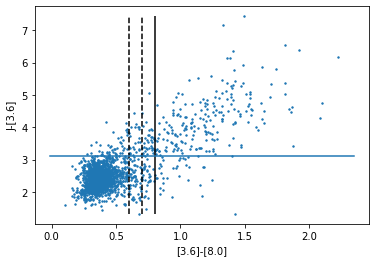

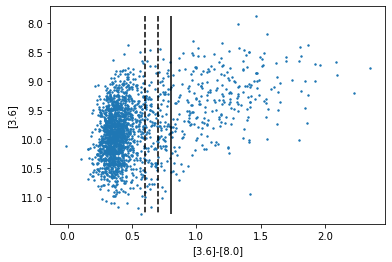

Non-sortable star found at index  0 . Assumed to not be extreme.
Non-sortable star found at index  227 . Assumed to not be extreme.
Non-sortable star found at index  243 . Assumed to not be extreme.
Non-sortable star found at index  250 . Assumed to not be extreme.
Non-sortable star found at index  748 . Assumed to not be extreme.
Non-sortable star found at index  917 . Assumed to not be extreme.
Non-sortable star found at index  1035 . Assumed to not be extreme.
Non-sortable star found at index  1189 . Assumed to not be extreme.
Non-sortable star found at index  1331 . Assumed to not be extreme.
Non-sortable star found at index  1339 . Assumed to not be extreme.
Non-sortable star found at index  1385 . Assumed to not be extreme.
Non-sortable star found at index  1597 . Assumed to not be extreme.


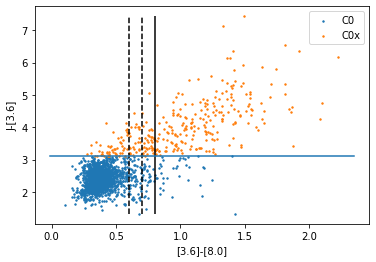

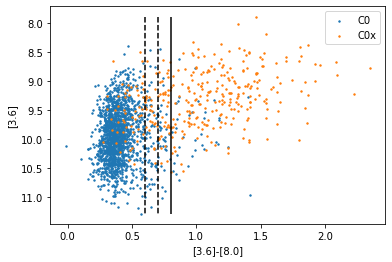

In [57]:
C0StarData_n,C0StarData_x  = sort_xC0(C0StarData)

In [58]:
#M0_reduced_for_36_minus_80 = clear_rows_with_nAn_for_color (M0StarData, ThreePointSixIndex, EightPointZeroIndex)
#M0_color_36_minus_80 = calculate_color (M0_reduced_for_36_minus_80[ThreePointSixIndex],M0_reduced_for_36_minus_80[EightPointZeroIndex])

#M1_reduced_for_36_minus_80 = clear_rows_with_nAn_for_color (M1StarData, ThreePointSixIndex, EightPointZeroIndex)
#M1_reduced_for_36_minus_80 = clear_rows_with_color_less_than_value (M1_reduced_for_36_minus_80, ThreePointSixIndex, EightPointZeroIndex,value=-0.25)
#print(M1_reduced_for_36_minus_80)
#M1_color_36_minus_80 = calculate_color (M1_reduced_for_36_minus_80[ThreePointSixIndex],M1_reduced_for_36_minus_80[EightPointZeroIndex])

#C0_reduced_for_36_minus_80 = clear_rows_with_nAn_for_color (C0StarData, ThreePointSixIndex, EightPointZeroIndex)
#C0_reduced_for_36_minus_80 = clear_rows_with_color_less_than_value (C0_reduced_for_36_minus_80, ThreePointSixIndex, EightPointZeroIndex,value=0)
#C0_color_36_minus_80 = calculate_color (C0_reduced_for_36_minus_80[ThreePointSixIndex],C0_reduced_for_36_minus_80[EightPointZeroIndex])

#C1_reduced_for_36_minus_80 = clear_rows_with_nAn_for_color (C1StarData, ThreePointSixIndex, EightPointZeroIndex)
#C1_color_36_minus_80 = calculate_color (C1_reduced_for_36_minus_80[ThreePointSixIndex],C1_reduced_for_36_minus_80[EightPointZeroIndex])


print('Calculating colors for M0 stars...')
M0_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (M0StarData, KIndex, EightPointZeroIndex)
M0_color_K_minus_80 = calculate_color (M0_reduced_for_K_minus_80[KIndex],M0_reduced_for_K_minus_80[EightPointZeroIndex])

print('Calculating colors for M1 stars...')
M1_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (M1StarData, KIndex, EightPointZeroIndex)
M1_reduced_for_K_minus_80 = clear_rows_with_color_less_than_value (M1_reduced_for_K_minus_80, KIndex, EightPointZeroIndex,value=0)
M1_color_K_minus_80 = calculate_color (M1_reduced_for_K_minus_80[KIndex],M1_reduced_for_K_minus_80[EightPointZeroIndex])

print('Calculating colors for C0 stars...')
C0_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (C0StarData_n, KIndex, EightPointZeroIndex)
C0_reduced_for_K_minus_80 = clear_rows_with_color_less_than_value (C0_reduced_for_K_minus_80, KIndex, EightPointZeroIndex,value=0)
C0_color_K_minus_80 = calculate_color (C0_reduced_for_K_minus_80[KIndex],C0_reduced_for_K_minus_80[EightPointZeroIndex])

print('Calculating colors for C0x stars...')
C0x_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (C0StarData_x, KIndex, EightPointZeroIndex)
C0x_reduced_for_K_minus_80 = clear_rows_with_color_less_than_value (C0x_reduced_for_K_minus_80, KIndex, EightPointZeroIndex,value=0)
C0x_color_K_minus_80 = calculate_color (C0x_reduced_for_K_minus_80[KIndex],C0x_reduced_for_K_minus_80[EightPointZeroIndex])

print('Calculating colors for C1 stars...')
C1_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (C1StarData, KIndex, EightPointZeroIndex)
C1_color_K_minus_80 = calculate_color (C1_reduced_for_K_minus_80[KIndex],C1_reduced_for_K_minus_80[EightPointZeroIndex])

Calculating colors for M0 stars...
Stars removed (nAn): 9
Calculating colors for M1 stars...
Stars removed (nAn): 6
Stars removed (color<0): 1
Calculating colors for C0 stars...
Stars removed (nAn): 22
Stars removed (color<0): 1
Calculating colors for C0x stars...
Stars removed (nAn): 26
Stars removed (color<0): 0
Calculating colors for C1 stars...
Stars removed (nAn): 2


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:27: DeprecationWarning: using a non-integer array as obj in delete will result in an error in the future


In [59]:
# Calculates the mass-loss rate from a hyperbolic fit to color
#                  a
#   log Mdot = _________ + c
#              color + b
def calc_mdot_from_color (color_data, a, b, c): # Color_data should be a numpy array. Using the function written, turn it into Mdot data for a given star type
    color_log_mdot = a/(color_data+b) + c 
    return color_log_mdot

In [60]:
def plot_x_y_data (xdata,ydata):
    plot.scatter(xdata,ydata,s=2)
    plot.show()
    plot.close()

In [61]:
# First, define function for ODR
def f10(B, x):
    '''Multi-Linear function y = B[0]*x0 + B[1]*x[1] + B[2]'''
    # B is a vector of the parameters.
    # x is an array of the current x values.
    # x is in the same format as the x passed to Data or RealData.
    #
    # Return an array in the same format as y passed to Data or RealData.
    return B[0]*x + B[1]
def do_odr_fit (data_to_fit):
    linear = Model(f10)
    logMdotData = np.log10(data_to_fit[5])
    logPData = np.log10(data_to_fit[13])
    logLData = np.log10(data_to_fit[8])
    mydata = Data(logPData,logMdotData)
    myodr = ODR(mydata,linear,beta0=[1,1,1])
    myrun = myodr.run()
    myrun.pprint()
    return myrun.beta # Return the information we need to create the fitting function and plot it

In [62]:
def chi_sq_fit_2d (data_x, data_y, print_model_results = 0):
    # First, let's look at all of the Fundamental mode data at once.
    # Convert the data into a Pandas DataFrame to use the formulas framework
    # in statsmodels

    # First we need to flatten the data: it's 2D layout is not relevent.
    x = data_x
    y = data_y

    data = pandas.DataFrame({'x': data_x, 'y': data_y})

    # Fit the model
    model = ols("y ~ x ", data).fit()

    # Print the summary
    if print_model_results != 0:
        print(model.summary())

        print("\nRetrieving manually the parameter estimates:")
        print(model._results.params)

        print("\nRetrieving manually the R^2 value:")
        print(model._results.rsquared)
        # Peform analysis of variance on fitted linear model
        anova_results = anova_lm(model)
        print('\nANOVA results')
        print(anova_results)
        
    parameters = model._results.params
    rsquared = model._results.rsquared
    return parameters, rsquared


In [63]:
chi_sq_fit_2d (np.log10(M0StarData[PIndex]), np.log10(M0StarData[MdotIndex]))

(array([-9.12945005,  1.07245939]), 0.13555362512130098)

In [64]:
def calc_PE_scale (stellar_data):
    Mass = stellar_data[MIndex]
    Radius = stellar_data[RIndex]
    potential_energy_scale = np.log10(Mass/Radius)
    return potential_energy_scale

def calc_g_scale (stellar_data):
    Mass = stellar_data[MIndex]
    Radius = stellar_data[RIndex]
    g_scale = np.log10(Mass/Radius**2)
    return g_scale

def calc_lum_pressure_scale (stellar_data):
    Luminosity = stellar_data[LIndex]
    Radius = stellar_data[RIndex]
    L_Pressure_scale = np.log10(Luminosity/Radius**2)
    return L_Pressure_scale

def calc_core_lum_param (stellar_data):
    Luminosity = stellar_data[LIndex]
    Mass = stellar_data[MIndex]
    core_lum_param = np.log10(Luminosity/Mass)
    return core_lum_param

In [65]:
def plot_logmdot_vs_parameter (mdot, parameter, title='', parameter_label='',save_fig = 0, save_folder = '',testing = 0):
    plot.scatter(parameter,mdot,s=2,label='Data')
    chisqparams = chi_sq_fit_2d (parameter, mdot)
    fit_parameters = chisqparams[0]
    fit_x = np.asarray([np.nanmin(parameter), np.nanmax(parameter)])
    if testing != 0:
        print('parameter:',parameter)
        print('np.min(parameter):',np.nanmin(parameter))
        print('np.max(parameter):',np.nanmax(parameter))
        print('fit_x:',fit_x)
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    if testing != 0:
        print('fit_y:',fit_x)
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*('+parameter_label+'); R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    plot.title(title)
    plot.xlabel(parameter_label)
    plot.ylabel('logMdot_obsv')
    plot.legend()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_versus_' + parameter_label + '/' + title
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()

In [66]:
def plot_residual_vs_parameter (mdot_resid, parameter, title='', parameter_label='',save_fig = 0, save_folder = ''):
    plot.scatter(parameter,mdot_resid,s=2, label = 'Data')
    chisqparams = chi_sq_fit_2d (parameter, mdot_resid)
    fit_parameters = chisqparams[0]
    fit_x = np.asarray([np.nanmin(parameter), np.nanmax(parameter)])
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*('+parameter_label+'); R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    plot.title(title)
    plot.xlabel(parameter_label)
    plot.ylabel('logMdot_calc-logMdot_obsv')
    plot.legend()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'Residuals/'+ 'residual_versus_'+ parameter_label + '/' + title
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()
    return fit_parameters

In [67]:
def plot_logmdot_vs_logmdot (mdot, calc_mdot, title='',save_fig = 0, save_folder = ''):
    plot.scatter(mdot,calc_mdot,s=2, label = 'Data')
    chisqparams = chi_sq_fit_2d (mdot, calc_mdot)
    fit_parameters = chisqparams[0]
    line_coords = np.asarray([np.min([np.nanmin(mdot),np.nanmin(calc_mdot)]),np.nanmax([np.max(mdot),np.nanmax(calc_mdot)])])
    fit_x = line_coords
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*'+'logMdot_obsv'+'; R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(line_coords,line_coords,color='black', label = '1:1 Line')
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    plot.title(title)
    plot.xlabel('logMdot_obsv')
    plot.ylabel('logMdot_calc')
    plot.legend()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_calc_versus_logMdot_obsv' + '/' + title
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()

In [68]:
def full_parameter_analysis (stellar_data_x, stellar_data_mdot, full_stellar_data, stellar_data_xlabel='', plot_label = '', save_folder = '', save_fig = 0):
    # Data Analysis: Do a chi^2 fit of our chosen parameter vs Mdot for our star, and find the residuals of that fit
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,stellar_data_mdot)
    Betas = chisqfit_returns[0]
    RSquared = chisqfit_returns[1]
    print('\n Fit: logMdot=', Betas[1],'*x+',Betas[0])
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    # First Plot: Chosen Parameter vs Mdot, so we can see what the chi^2 fit looks like
    plot_logmdot_vs_parameter (stellar_data_mdot, stellar_data_x, title=plot_label, parameter_label=stellar_data_xlabel,save_folder = save_folder,save_fig = save_fig)
    #plot.scatter(stellar_data_x,stellar_data_mdot,s=2)
    #fit_x = np.asarray([np.min(stellar_data_x), np.max(stellar_data_x)])
    #fit_y = Betas[0] + Betas[1]*fit_x
    #plot.plot(fit_x,fit_y,color='orange')
    #plot.xlabel(stellar_data_xlabel)
    #plot.ylabel('logMdot_obsv')
    #plot.title(plot_label)
    #plot.show()
    #plot.close()
    # Data Analysis: For the input, calculate some proxies for stellar parameters (so they don't have to be fed to the function indvidually)
    logPE = calc_PE_scale(full_stellar_data)
    logg = calc_g_scale(full_stellar_data)
    logLP = calc_lum_pressure_scale(full_stellar_data)
    logCL = calc_core_lum_param(full_stellar_data)
    # More plots
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[PIndex]),title=plot_label,parameter_label='logP',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[LIndex]),title=plot_label,parameter_label='logL',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[MIndex]),title=plot_label,parameter_label='logM',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logPE,title=plot_label,parameter_label='log(M/R)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logg,title=plot_label,parameter_label='log(M/R^2)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logLP,title=plot_label,parameter_label='log(L/R^2)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logCL,title=plot_label,parameter_label='log(L/M)',save_folder = save_folder,save_fig = save_fig)
    
    color_J_minus_ThreePointSix = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[ThreePointSixIndex])
    color_ThreePointSix_minus_EightPointZero = np.asarray(full_stellar_data[ThreePointSixIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    color_J_minus_K = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[KIndex])
    color_K_minus_EightPointZero = np.asarray(full_stellar_data[KIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    plot_logmdot_vs_parameter (stellar_data_mdot,color_ThreePointSix_minus_EightPointZero , title=plot_label, parameter_label='[3.6]-[8.0]')
    plot_logmdot_vs_parameter (stellar_data_mdot, color_K_minus_EightPointZero, title=plot_label, parameter_label='K-[8.0]')
    plot_residual_vs_parameter(logMdot_residual,color_ThreePointSix_minus_EightPointZero,title=plot_label,parameter_label='[3.6]-[8.0]',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,color_K_minus_EightPointZero,title=plot_label,parameter_label='K-[8.0]',save_folder = save_folder,save_fig = save_fig)
    
    plot_logmdot_vs_logmdot(stellar_data_mdot, logMdot_calc, title=plot_label,save_folder = save_folder,save_fig = save_fig)

In [69]:
def hyperbolic_func (C, P0, P1, P2):
    # logMdot = a/(C + b) + c
    return ((P0/(C+P1)))+P2 

In [91]:
def fit_to_hyperbolic (xdata, ydata, save_fig = 0, plot_title = '', x_label='',y_label='', save_folder = '', flip_axes = 0, z_color_by_data=[],manual_data_bin_tau=0, z_data_to_sort=[],initial_guess=[]):
    if len (initial_guess) >0:
        fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func, xdata, ydata,p0=initial_guess)
    else:
        fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func, xdata, ydata)
    fit_left = np.min(xdata)
    fit_right = np.max(xdata)
    #print(fit_left,fit_right)
    fit_data = [fit_left]
    new_elem = fit_left + np.abs((fit_right-fit_left))/100
    while len(fit_data)<100:
        fit_data.append(new_elem)
        new_elem = new_elem + np.abs((fit_right-fit_left))/100
    #print(fit_data)
    fit_curve = hyperbolic_func (fit_data, fit_parameters[0], fit_parameters[1], fit_parameters[2])
    fit_y = hyperbolic_func (xdata, fit_parameters[0], fit_parameters[1], fit_parameters[2])
    if flip_axes == 0:
        if len(z_color_by_data)>0: 
            plot.scatter(xdata, ydata, label='Data',s=2,c=z_color_by_data,cmap='Dark2')
        elif manual_data_bin_tau >0:
            zdata = np.asarray(z_data_to_sort)
            data_to_sort = np.transpose(np.asarray([xdata, ydata, zdata])) # Stack our data so we can associate data points with each other
            a = data_to_sort
            ind=np.argsort(a[:,-1])
            sorted_data=np.transpose(np.asarray(a[ind]))
            #print('sorted_data:',sorted_data)
            #print(len(data_to_sort))
            #print('sorted_data:',sorted_data)
            #print(data_to_sort)
            bin_size = len(data_to_sort)//manual_data_bin_tau
            bin_bottom = 0
            bin_top = bin_size
            #print('len(data_to_sort):',len(data_to_sort))
            i=0
            while i < manual_data_bin_tau:
                if i ==0: # When on first bin
                    working_x=sorted_data[0][:bin_top]
                    working_y=sorted_data[1][:bin_top]
                    data_label = 'tau<'+str( np.max(sorted_data[2][:bin_size]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                elif i == manual_data_bin_tau-1: # If we are on the last bin
                    working_x=sorted_data[0][bin_bottom:]
                    working_y=sorted_data[1][bin_bottom:]
                    data_label = 'tau>'+str(np.min(sorted_data[2][bin_bottom:]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                else: # We are on some intermediate bin
                    working_x=sorted_data[0][bin_bottom:bin_top]
                    working_y=sorted_data[1][bin_bottom:bin_top]
                    #print('tau range:',sorted_data[2][bin_bottom:bin_top])
                    data_label = str(np.min(sorted_data[2][bin_bottom:bin_top]))[0:7] +'<tau<'+str(np.max(sorted_data[2][bin_bottom:bin_top]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                bin_bottom = bin_bottom+bin_size
                print('bin_bottom:',bin_bottom)
                bin_top = bin_top + bin_size
                print('bin_top:',bin_top)
                i = i + 1
        else:
            plot.scatter(xdata, ydata, label='Data',s=2)
        plot.plot(fit_data,fit_curve,label='fit: a=%5.3f, b=%5.3f, c=%5.3f' % tuple(fit_parameters),color='orange')
        plot.title(plot_title)
        plot.legend()
        plot.ylim((np.min(ydata)-0.1), (np.max(ydata)+0.1))
        plot.xlabel(x_label)
        plot.ylabel(y_label)
        if save_fig !=0:
            plot.savefig(save_folder+'/'+plot_title+y_label+'_vs_'+x_label+'.png')
            plot.savefig(save_folder+'/'+plot_title+y_label+'_vs_'+x_label+'.pdf')
            plot.close()
        else:
            plot.show()
            plot.close()
    else:
        if len(z_color_by_data)>0: 
            plot.scatter(xdata, ydata, label='Data',s=2,c=z_color_by_data,cmap='Dark2')
        elif manual_data_bin_tau >0:
            zdata = np.asarray(z_data_to_sort)
            data_to_sort = np.transpose(np.asarray([xdata, ydata, zdata])) # Stack our data so we can associate data points with each other
            a = data_to_sort
            ind=np.argsort(a[:,-1])
            sorted_data=np.transpose(np.asarray(a[ind]))
            print('sorted_data:',sorted_data)
            #print(len(data_to_sort))
            #print('sorted_data:',sorted_data)
            #print(data_to_sort)
            bin_size = len(data_to_sort)//manual_data_bin_tau
            bin_bottom = 0
            bin_top = bin_size
            print('len(data_to_sort):',len(data_to_sort))
            i=0
            while i < manual_data_bin_tau:
                if i ==0: # When on first bin
                    working_x=sorted_data[0][:bin_top]
                    working_y=sorted_data[1][:bin_top]
                    data_label = 'tau<'+str( np.max(sorted_data[2][:bin_size]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                elif i == manual_data_bin_tau-1: # If we are on the last bin
                    working_x=sorted_data[0][bin_bottom:]
                    working_y=sorted_data[1][bin_bottom:]
                    data_label = 'tau>'+str(np.min(sorted_data[2][bin_bottom:]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                else: # We are on some intermediate bin
                    working_x=sorted_data[0][bin_bottom:bin_top]
                    working_y=sorted_data[1][bin_bottom:bin_top]
                    #print('tau range:',sorted_data[2][bin_bottom:bin_top])
                    data_label = str(np.min(sorted_data[2][bin_bottom:bin_top]))[0:7] +'<tau<'+str(np.max(sorted_data[2][bin_bottom:bin_top]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                bin_bottom = bin_bottom+bin_size
                print('bin_bottom:',bin_bottom)
                bin_top = bin_top + bin_size
                print('bin_top:',bin_top)
                i = i + 1
        else:
            plot.scatter(xdata, ydata, label='Data',s=2)
        plot.plot(fit_curve,fit_data,label='fit: a=%5.3f, b=%5.3f, c=%5.3f' % tuple(fit_parameters),color='orange')
        plot.title(plot_title)
        plot.legend()
        plot.xlabel(y_label)
        plot.ylabel(x_label)
        if save_fig !=0:
            plot.savefig(save_folder+'/'+plot_title+y_label+'_vs_'+x_label+'.png')
            plot.savefig(save_folder+'/'+plot_title+y_label+'_vs_'+x_label+'.pdf')
            plot.close()
        else:
            plot.show()
            plot.close()
            
    # Plot 2: logMdot_GRAMS vs logMdot_color
    plot.scatter(fit_y,ydata,label='Data',s=2)
    plot.title(plot_title)
    #print(np.min(ydata),np.min(fit_y))
    bottom_left = np.min([np.min(ydata),np.min(fit_y)])-0.1
    top_right = np.max([np.max(ydata),np.max(fit_y)])+0.1
    fit_parameters_2, r2_parameters_2 = chi_sq_fit_2d (fit_y,ydata)
    fit_line = np.asarray([fit_parameters_2[1]*bottom_left + fit_parameters_2[0], fit_parameters_2[1]*top_right + fit_parameters_2[0]])
    OneToOneData=[bottom_left,top_right]
    plot.plot(OneToOneData, fit_line,marker='.',label='fit: int.=%5.3f, slope.=%5.3f' % tuple(fit_parameters_2),color='orange')
    OneToOneData=[bottom_left,top_right]
    plot.plot(OneToOneData, OneToOneData,color='k',marker='.')
    #print(bottom_left,top_right)
    plot.xlim(bottom_left, top_right)
    plot.ylim(bottom_left, top_right)
    plot.xlabel('logMdot_1color')
    plot.ylabel('logMdot_GRAMS')
    plot.legend()
    if save_fig !=0:
        plot.savefig(save_folder+'/'+plot_title+'logMdot_GRAMS'+'_vs_'+'logMdot_1color'+'.png')
        plot.savefig(save_folder+'/'+plot_title+'logMdot_GRAMS'+'_vs_'+'logMdot_1color'+'.pdf')
        plot.close()
    else:
        plot.show()
        plot.close()
        
        
    # Plot 3: Histogram of Residuals. We want to know which has the smallest range for the C0 Stars.
    hist_data = fit_y-ydata # New Residual, after applying 2nd color correction
    n, bins, patches = plot.hist(hist_data,bins=10) # Histogram of residual logMdot_color-logMdot_GRAMS
    #print('n:',n)
    #print('np.max(n):',np.max(n))
    standard_dev = hist_data.std()
    #print('Standard Dev.', standard_dev)
    mean = hist_data.mean()
    #print('mean:',mean)
    hist_left=np.min(hist_data)
    hist_right=np.max(hist_data)
    
    normal_sample = [hist_left]
    new_elem_norm_samp = hist_left + np.abs((hist_right-hist_left))/100
    while len(normal_sample)<100:
        normal_sample.append(new_elem_norm_samp)
        new_elem_norm_samp = new_elem_norm_samp + np.abs((hist_right-hist_left))/100
    #print(normal_sample)
    # f(x) = 1/(sigma*sqrt(2*pi))*exp(-1/2*((x-mean)/sigma)**2)
    normal_func = (1/(standard_dev*np.sqrt(2*np.pi)) )*np.exp(-0.5*((normal_sample-mean)/standard_dev)**2)
    normal_func = np.max(n)/np.max(normal_func)*normal_func
    #print(normal_func)
    plot.plot(normal_sample,normal_func,ls='--',marker='',label='normal: std=%5.3f, mean=%5.3f' % tuple([standard_dev,mean]))
    plot.xlabel('logMdot_1color-logMdot_GRAMS')
    plot.ylabel('N')
    plot.title(plot_title)
    plot.legend()
    if save_fig !=0:
        plot.savefig(save_folder+'/'+plot_title+'Hist_logMdot_1color-logMdot_GRAMS'+'.png')
        plot.savefig(save_folder+'/'+plot_title+'Hist_logMdot_1color-logMdot_GRAMS'+'.pdf')
        plot.close()
    else:
        plot.show()
        plot.close()
        
    # Plot 4: Residual vs Color
    plot.scatter(xdata,hist_data,s=2)
    plot.title(plot_title)
    plot.ylabel('logMdot_1color-logMdot_GRAMS')
    plot.xlabel(x_label)
    residual_parameters_plot_4, residual_r2_plot_4 = chi_sq_fit_2d (xdata,hist_data)
    #print('np.nanmin(xdata[0]):',np.nanmin(xdata[0]))
    #print('np.nanmax(xdata[0]):',np.nanmax(xdata[0]))
    lr_bounds = np.asarray([np.nanmin(xdata),np.nanmax(xdata)])
    tb_values = residual_parameters_plot_4[1]*lr_bounds+residual_parameters_plot_4[0]
    #print('tb_values:',tb_values)
    plot.plot(lr_bounds,tb_values,marker='',label='fit: int.=%5.3f, slope.=%5.3f' % tuple(residual_parameters_plot_4),color='orange')
    plot.legend()
    #plot.plot(lr_bounds,tb_values,marker='')
    if save_fig !=0:
        plot.savefig(save_folder+'/'+plot_title+'Residual_vs_Color'+'.png')
        plot.savefig(save_folder+'/'+plot_title+'Residual_vs_Color'+'.pdf')
        plot.close()
    else:
        plot.show()
        plot.close()
    
    return [fit_parameters[0], fit_parameters[1], fit_parameters[2]]

In [92]:
Directory = 'Single_Parameter_Fits/color_Mdot'
M0_color_coeffs = fit_to_hyperbolic(M0_color_K_minus_80,np.log10(M0_reduced_for_K_minus_80[MdotIndex]), plot_title='M0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M0_reduced_for_K_minus_80[tauIndex],save_fig=1, save_folder =  Directory)
M1_color_coeffs = fit_to_hyperbolic(M1_color_K_minus_80,np.log10(M1_reduced_for_K_minus_80[MdotIndex]), plot_title='M1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M1_reduced_for_K_minus_80[tauIndex],save_fig=1, save_folder =  Directory)
C0_color_coeffs = fit_to_hyperbolic(C0_color_K_minus_80,np.log10(C0_reduced_for_K_minus_80[MdotIndex]), plot_title='C0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0_reduced_for_K_minus_80[tauIndex],save_fig=1, save_folder =  Directory)
C1_color_coeffs = fit_to_hyperbolic(C1_color_K_minus_80,np.log10(C1_reduced_for_K_minus_80[MdotIndex]), plot_title='C1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=3, z_data_to_sort=C1_reduced_for_K_minus_80[tauIndex],save_fig=1, save_folder =  Directory)
C0x_color_coeffs = fit_to_hyperbolic(C0x_color_K_minus_80,np.log10(C0x_reduced_for_K_minus_80[MdotIndex]), plot_title='C0x', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0x_reduced_for_K_minus_80[tauIndex],initial_guess = C0_color_coeffs,save_fig=1, save_folder =  Directory )

bin_bottom: 485
bin_top: 970
bin_bottom: 970
bin_top: 1455
bin_bottom: 1455
bin_top: 1940
bin_bottom: 1940
bin_top: 2425
bin_bottom: 538
bin_top: 1076
bin_bottom: 1076
bin_top: 1614
bin_bottom: 1614
bin_top: 2152
bin_bottom: 2152
bin_top: 2690
bin_bottom: 407
bin_top: 814
bin_bottom: 814
bin_top: 1221
bin_bottom: 1221
bin_top: 1628
bin_bottom: 1628
bin_top: 2035
bin_bottom: 259
bin_top: 518
bin_bottom: 518
bin_top: 777
bin_bottom: 777
bin_top: 1036
bin_bottom: 78
bin_top: 156
bin_bottom: 156
bin_top: 234
bin_bottom: 234
bin_top: 312
bin_bottom: 312
bin_top: 390


In [19]:
# For now, see file "Color Fits - Multiple Colors and Residual Reduction, Algebraic" for calculation of these coefficients.

M0_color_Mdot = calc_mdot_from_color (M0_color_K_minus_80, -1.112, 0.321, -5.413)
M1_color_Mdot = calc_mdot_from_color (M1_color_K_minus_80, -2.852, 0.648, -4.186)
C0_color_Mdot = calc_mdot_from_color (C0_color_K_minus_80, -4.878, 1.152, -4.390)
C0x_color_Mdot = calc_mdot_from_color (C0x_color_K_minus_80, -23.407, 4.806, -2.481)
C1_color_Mdot = calc_mdot_from_color (C1_color_K_minus_80, -11.274, 2.246, -3.194)

M0:

 Fit: logMdot= 0.39720483968729936 *x+ -7.650829875489846


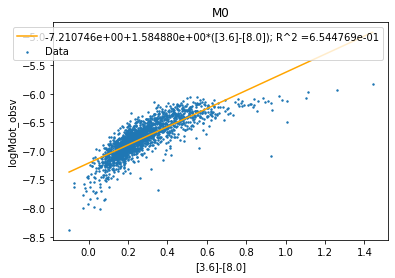

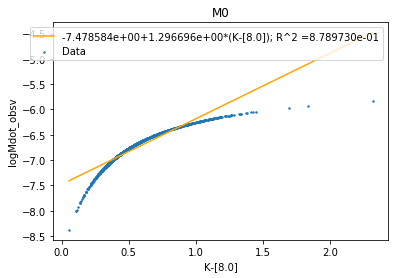


M1:

 Fit: logMdot= 0.9027182767967955 *x+ -8.65733482195609


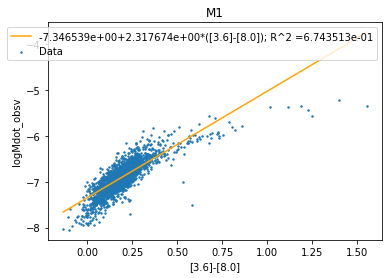

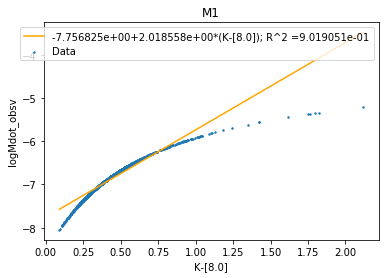


C0

 Fit: logMdot= 0.5862556938553908 *x+ -8.10991286176528


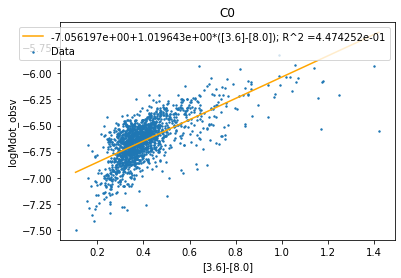

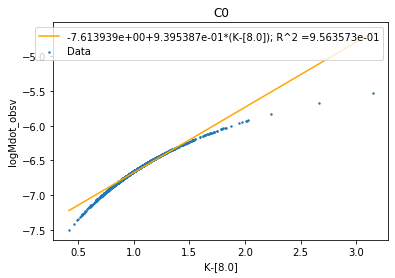


C0x

 Fit: logMdot= 1.1212851725023516 *x+ -8.680980211693408


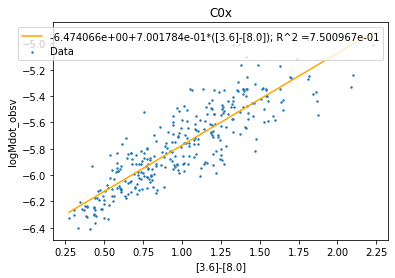

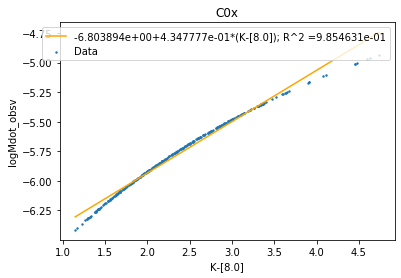


C1

 Fit: logMdot= 1.211616280969335 *x+ -9.377291494407793


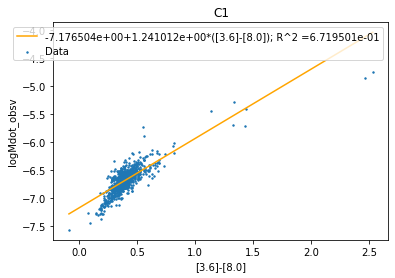

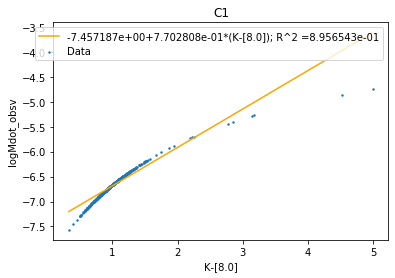

In [20]:
Directory = 'Single_Parameter_Fits/color_Mdot/logP'
print('M0:')
full_parameter_analysis (np.log10(M0_reduced_for_K_minus_80[PIndex]), M0_color_Mdot, M0_reduced_for_K_minus_80, stellar_data_xlabel='log(P)', plot_label='M0', save_fig = 1, save_folder=Directory)
print('\nM1:')
full_parameter_analysis (np.log10(M1_reduced_for_K_minus_80[PIndex]), M1_color_Mdot, M1_reduced_for_K_minus_80, stellar_data_xlabel='log(P)', plot_label='M1', save_fig = 1, save_folder=Directory)
print('\nC0')
full_parameter_analysis (np.log10(C0_reduced_for_K_minus_80[PIndex]), C0_color_Mdot, C0_reduced_for_K_minus_80, stellar_data_xlabel='log(P)', plot_label='C0', save_fig = 1, save_folder=Directory)
print('\nC0x')
full_parameter_analysis (np.log10(C0x_reduced_for_K_minus_80[PIndex]), C0x_color_Mdot, C0x_reduced_for_K_minus_80, stellar_data_xlabel='log(P)', plot_label='C0x', save_fig = 1, save_folder=Directory)
print('\nC1')
full_parameter_analysis (np.log10(C1_reduced_for_K_minus_80[PIndex]), C1_color_Mdot, C1_reduced_for_K_minus_80, stellar_data_xlabel='log(P)', plot_label='C1', save_fig = 1, save_folder=Directory)

M0:

 Fit: logMdot= -0.2534829390574895 *x+ -5.884777274602043


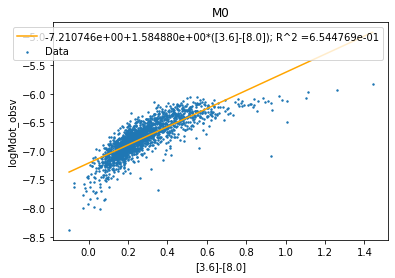

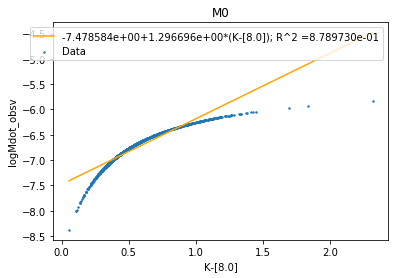


M1:

 Fit: logMdot= 0.4172899220416139 *x+ -8.39826753674976


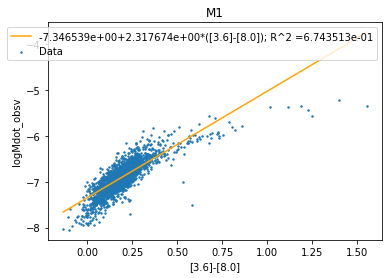

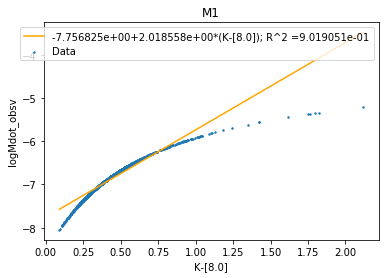


C0

 Fit: logMdot= 0.09343940489271865 *x+ -6.996534937500788


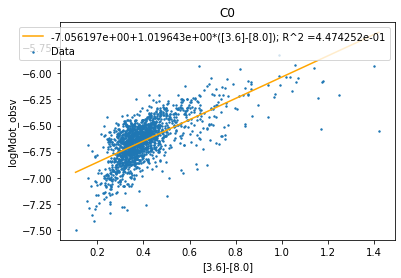

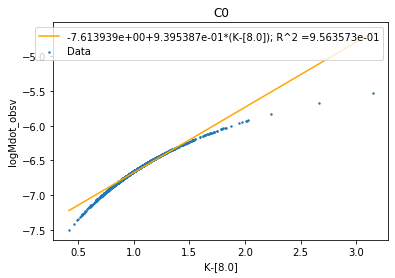


C0x

 Fit: logMdot= 0.27620516671828615 *x+ -6.8102150058586295


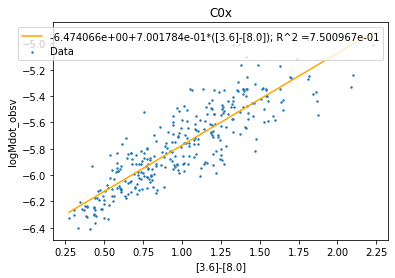

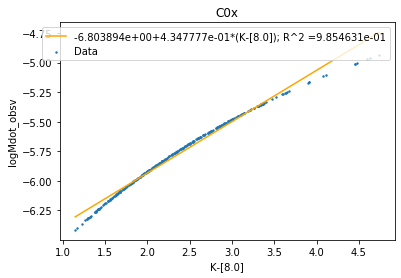


C1

 Fit: logMdot= 0.27679668786212464 *x+ -7.746311399106738


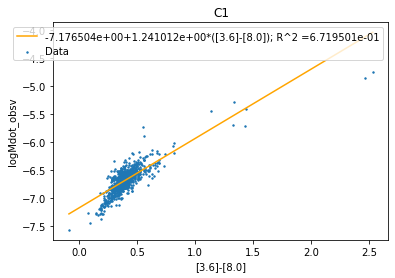

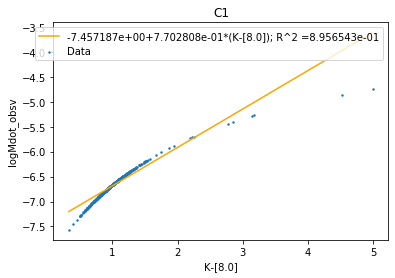

In [20]:
Directory = 'Single_Parameter_Fits/color_Mdot/logL'
print('M0:')
full_parameter_analysis (np.log10(M0_reduced_for_K_minus_80[LIndex]), M0_color_Mdot, M0_reduced_for_K_minus_80, stellar_data_xlabel='log(L)', plot_label='M0', save_fig = 1, save_folder=Directory)
print('\nM1:')
full_parameter_analysis (np.log10(M1_reduced_for_K_minus_80[LIndex]), M1_color_Mdot, M1_reduced_for_K_minus_80, stellar_data_xlabel='log(L)', plot_label='M1', save_fig = 1, save_folder=Directory)
print('\nC0')
full_parameter_analysis (np.log10(C0_reduced_for_K_minus_80[LIndex]), C0_color_Mdot, C0_reduced_for_K_minus_80, stellar_data_xlabel='log(L)', plot_label='C0', save_fig = 1, save_folder=Directory)
print('\nC0x')
full_parameter_analysis (np.log10(C0x_reduced_for_K_minus_80[LIndex]), C0x_color_Mdot, C0x_reduced_for_K_minus_80, stellar_data_xlabel='log(L)', plot_label='C0x', save_fig = 1, save_folder=Directory)
print('\nC1')
full_parameter_analysis (np.log10(C1_reduced_for_K_minus_80[LIndex]), C1_color_Mdot, C1_reduced_for_K_minus_80, stellar_data_xlabel='log(L)', plot_label='C1', save_fig = 1, save_folder=Directory)

M0:

 Fit: logMdot= -0.17991844731613466 *x+ -6.385364662873613


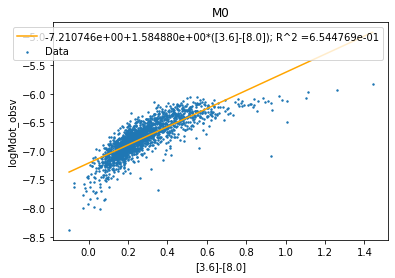

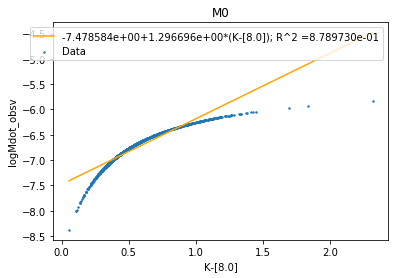


M1:

 Fit: logMdot= 0.8530496319362807 *x+ -8.805086290586145


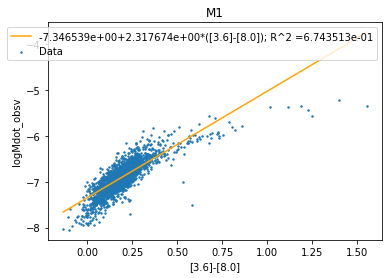

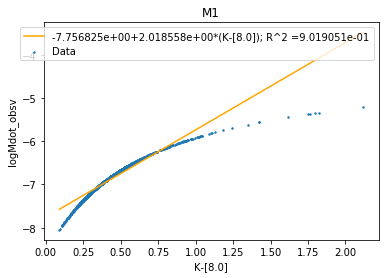


C0

 Fit: logMdot= 0.357834363230692 *x+ -7.505502231114119


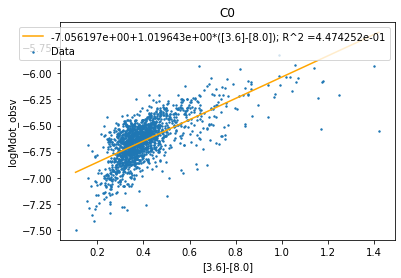

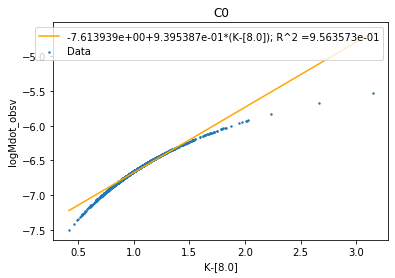


C0x

 Fit: logMdot= 0.7279633157768406 *x+ -7.53213791366702


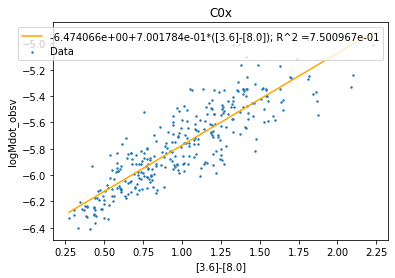

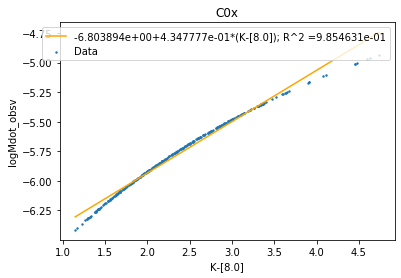


C1

 Fit: logMdot= 0.9895741104287529 *x+ -9.1161199525168


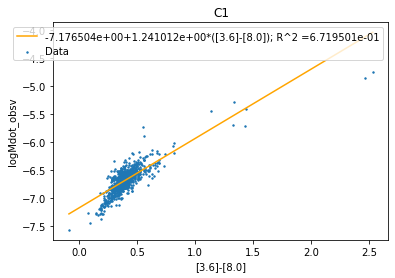

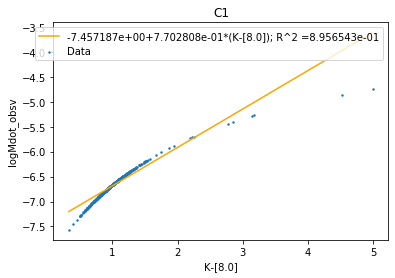

In [23]:
Directory = 'Single_Parameter_Fits/color_Mdot/logR'
print('M0:')
full_parameter_analysis (np.log10(M0_reduced_for_K_minus_80[RIndex]), M0_color_Mdot, M0_reduced_for_K_minus_80, stellar_data_xlabel='log(R)', plot_label='M0', save_fig = 1, save_folder=Directory)
print('\nM1:')
full_parameter_analysis (np.log10(M1_reduced_for_K_minus_80[RIndex]), M1_color_Mdot, M1_reduced_for_K_minus_80, stellar_data_xlabel='log(R)', plot_label='M1', save_fig = 1, save_folder=Directory)
print('\nC0')
full_parameter_analysis (np.log10(C0_reduced_for_K_minus_80[RIndex]), C0_color_Mdot, C0_reduced_for_K_minus_80, stellar_data_xlabel='log(R)', plot_label='C0', save_fig = 1, save_folder=Directory)
print('\nC0x')
full_parameter_analysis (np.log10(C0x_reduced_for_K_minus_80[RIndex]), C0x_color_Mdot, C0x_reduced_for_K_minus_80, stellar_data_xlabel='log(R)', plot_label='C0x', save_fig = 1, save_folder=Directory)
print('\nC1')
full_parameter_analysis (np.log10(C1_reduced_for_K_minus_80[RIndex]), C1_color_Mdot, C1_reduced_for_K_minus_80, stellar_data_xlabel='log(R)', plot_label='C1', save_fig = 1, save_folder=Directory)

M0:

 Fit: logMdot= -0.9447693808747282 *x+ -6.767085560581445


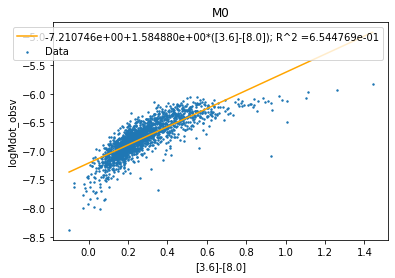

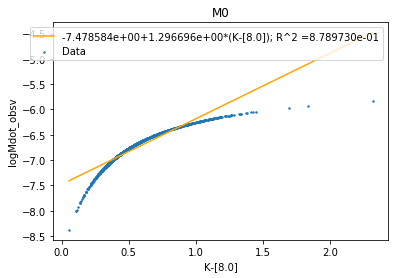


M1:

 Fit: logMdot= 0.1387948716994158 *x+ -6.90404450661042


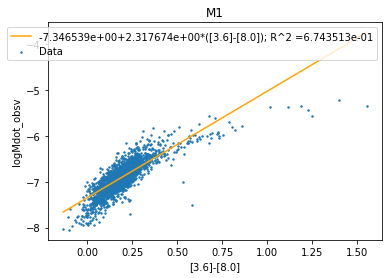

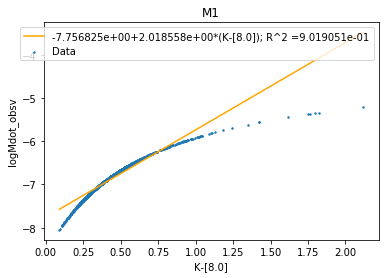


C0

 Fit: logMdot= -0.10588262009450716 *x+ -6.621084014178701


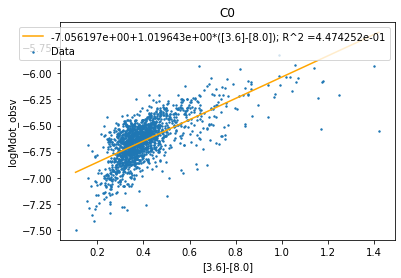

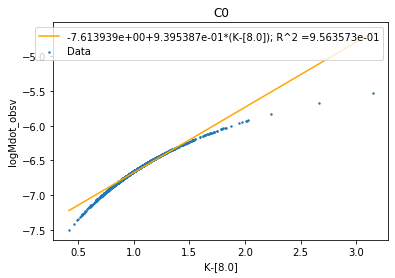


C0x

 Fit: logMdot= 0.16424904162838722 *x+ -5.785390889501039


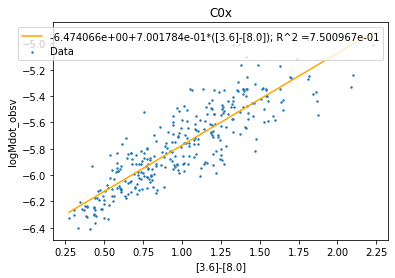

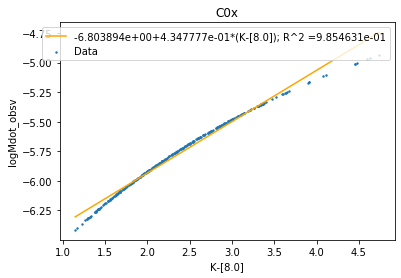


C1

 Fit: logMdot= -0.3515711073270479 *x+ -6.6175174261365965


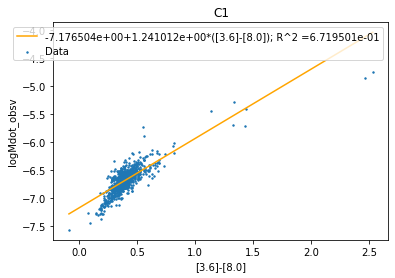

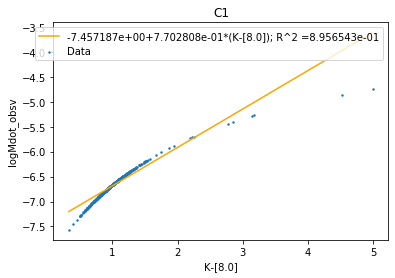

In [24]:
Directory = 'Single_Parameter_Fits/color_Mdot/logM'
print('M0:')
full_parameter_analysis (np.log10(M0_reduced_for_K_minus_80[MIndex]), M0_color_Mdot, M0_reduced_for_K_minus_80, stellar_data_xlabel='log(M)', plot_label='M0', save_fig = 1, save_folder=Directory)
print('\nM1:')
full_parameter_analysis (np.log10(M1_reduced_for_K_minus_80[MIndex]), M1_color_Mdot, M1_reduced_for_K_minus_80, stellar_data_xlabel='log(M)', plot_label='M1', save_fig = 1, save_folder=Directory)
print('\nC0')
full_parameter_analysis (np.log10(C0_reduced_for_K_minus_80[MIndex]), C0_color_Mdot, C0_reduced_for_K_minus_80, stellar_data_xlabel='log(M)', plot_label='C0', save_fig = 1, save_folder=Directory)
print('\nC0x')
full_parameter_analysis (np.log10(C0x_reduced_for_K_minus_80[MIndex]), C0x_color_Mdot, C0x_reduced_for_K_minus_80, stellar_data_xlabel='log(M)', plot_label='C0x', save_fig = 1, save_folder=Directory)
print('\nC1')
full_parameter_analysis (np.log10(C1_reduced_for_K_minus_80[MIndex]), C1_color_Mdot, C1_reduced_for_K_minus_80, stellar_data_xlabel='log(M)', plot_label='C1', save_fig = 1, save_folder=Directory)

In [28]:
M0_logPE = calc_PE_scale(M0_reduced_for_K_minus_80)
M1_logPE = calc_PE_scale(M1_reduced_for_K_minus_80)
C0_logPE = calc_PE_scale(C0_reduced_for_K_minus_80)
C0x_logPE = calc_PE_scale(C0x_reduced_for_K_minus_80)
C1_logPE = calc_PE_scale(C1_reduced_for_K_minus_80)

M0_logg = calc_g_scale(M0_reduced_for_K_minus_80)
M1_logg = calc_g_scale(M1_reduced_for_K_minus_80)
C0_logg = calc_g_scale(C0_reduced_for_K_minus_80)
C0x_logg = calc_g_scale(C0x_reduced_for_K_minus_80)
C1_logg = calc_g_scale(C1_reduced_for_K_minus_80)

M0_logLP = calc_lum_pressure_scale(M0_reduced_for_K_minus_80)
M1_logLP = calc_lum_pressure_scale(M1_reduced_for_K_minus_80)
C0_logLP = calc_lum_pressure_scale(C0_reduced_for_K_minus_80)
C0x_logLP = calc_lum_pressure_scale(C0x_reduced_for_K_minus_80)
C1_logLP = calc_lum_pressure_scale(C1_reduced_for_K_minus_80)

M0_logCL = calc_core_lum_param(M0_reduced_for_K_minus_80)
M1_logCL = calc_core_lum_param(M1_reduced_for_K_minus_80)
C0_logCL = calc_core_lum_param(C0_reduced_for_K_minus_80)
C0x_logCL = calc_core_lum_param(C0x_reduced_for_K_minus_80)
C1_logCL = calc_core_lum_param(C1_reduced_for_K_minus_80)


 Fit: logMdot= -1.717485072478139 *x+ -10.515389112195633


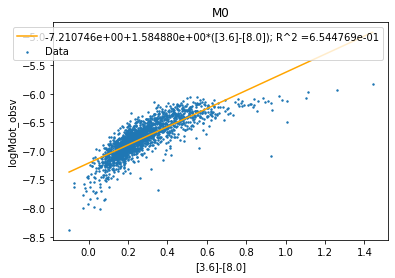

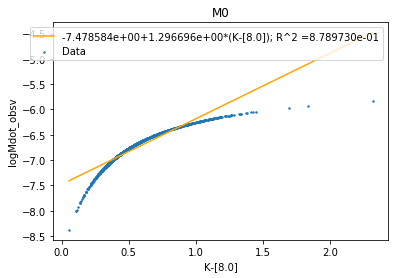


 Fit: logMdot= -1.8881536584747165 *x+ -11.100508141517857


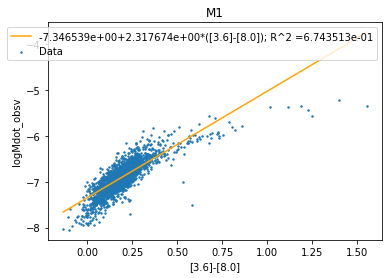

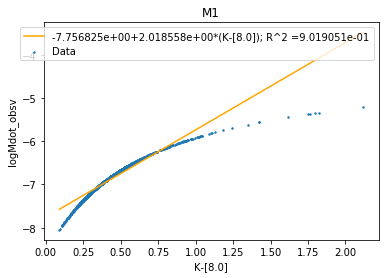


 Fit: logMdot= -0.8370084245632918 *x+ -8.51049246113835


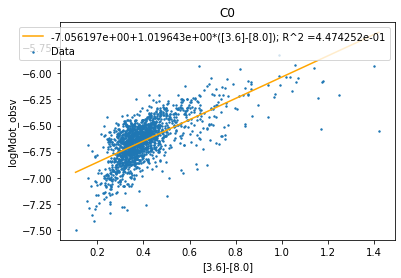

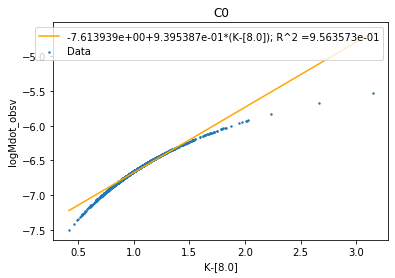


 Fit: logMdot= -0.9573254283521415 *x+ -8.01360806394284


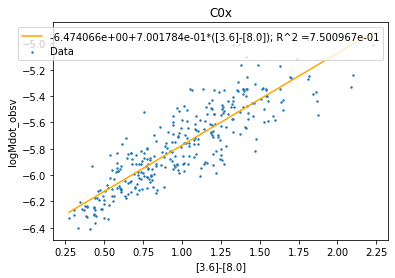

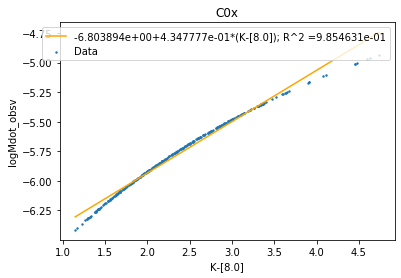


 Fit: logMdot= -1.3037528136377263 *x+ -9.675037803862274


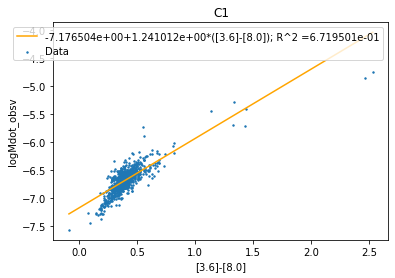

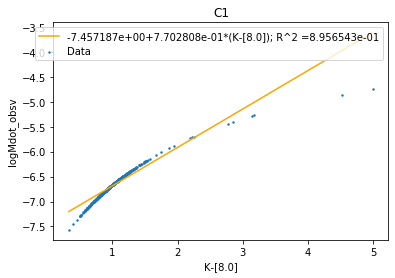

In [29]:
Directory = 'Single_Parameter_Fits/color_Mdot/log(M/R)'
full_parameter_analysis (M0_logPE, M0_color_Mdot, M0_reduced_for_K_minus_80, stellar_data_xlabel='log(M/R)', plot_label='M0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (M1_logPE, M1_color_Mdot, M1_reduced_for_K_minus_80, stellar_data_xlabel='log(M/R)', plot_label='M1', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0_logPE, C0_color_Mdot, C0_reduced_for_K_minus_80, stellar_data_xlabel='log(M/R)', plot_label='C0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0x_logPE, C0x_color_Mdot, C0x_reduced_for_K_minus_80, stellar_data_xlabel='log(M/R)', plot_label='C0x', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C1_logPE, C1_color_Mdot, C1_reduced_for_K_minus_80, stellar_data_xlabel='log(M/R)', plot_label='C1', save_fig = 1, save_folder=Directory)


 Fit: logMdot= -0.6256323547567655 *x+ -9.509063640056272


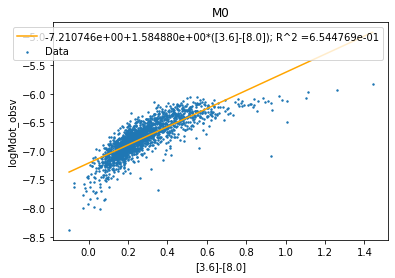

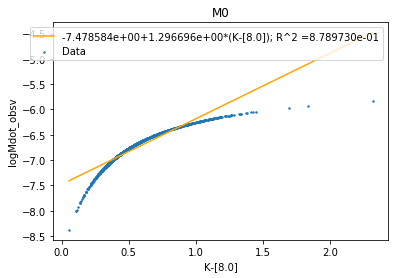


 Fit: logMdot= -0.888778475359991 *x+ -10.860507706174635


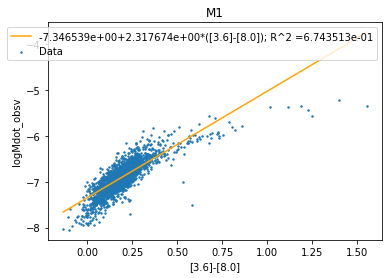

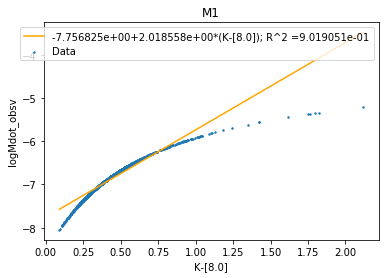


 Fit: logMdot= -0.7225604997677765 *x+ -10.001495662164222


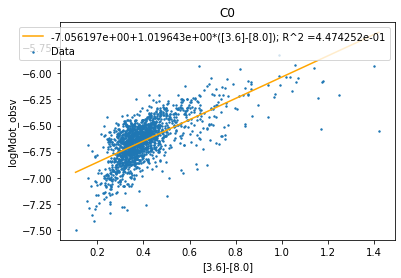

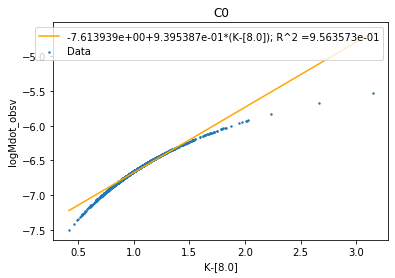


 Fit: logMdot= -1.541312313462102 *x+ -13.10531484081786


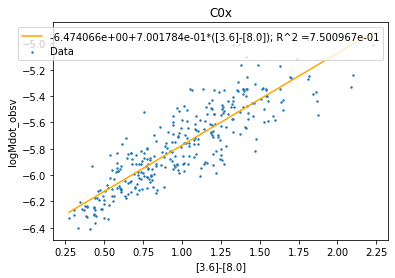

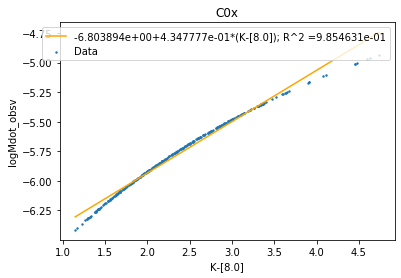


 Fit: logMdot= -1.0472726487976984 *x+ -11.667679615544472


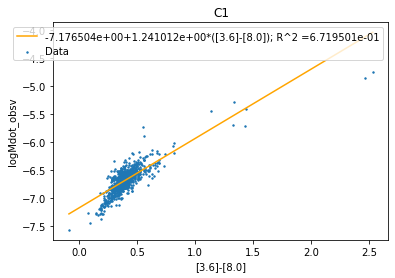

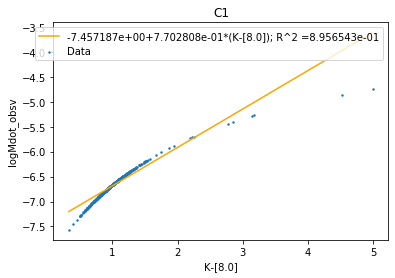

In [30]:
Directory = 'Single_Parameter_Fits/color_Mdot/log(M/R^2)'
full_parameter_analysis (M0_logg, M0_color_Mdot, M0_reduced_for_K_minus_80, stellar_data_xlabel='log(M/R^2)', plot_label='M0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (M1_logg, M1_color_Mdot, M1_reduced_for_K_minus_80, stellar_data_xlabel='log(M/R^2)', plot_label='M1', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0_logg, C0_color_Mdot, C0_reduced_for_K_minus_80, stellar_data_xlabel='log(M/R^2)', plot_label='C0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0x_logg, C0x_color_Mdot, C0x_reduced_for_K_minus_80, stellar_data_xlabel='log(M/R^2)', plot_label='C0x', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C1_logg, C1_color_Mdot, C1_reduced_for_K_minus_80, stellar_data_xlabel='log(M/R^2)', plot_label='C1', save_fig = 1, save_folder=Directory)


 Fit: logMdot= -3.1370744003480695 *x+ -9.440317853985007


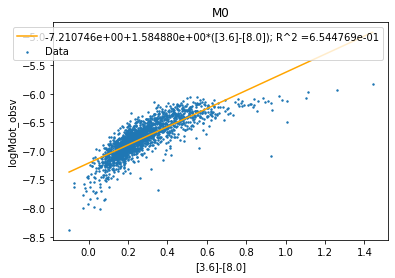

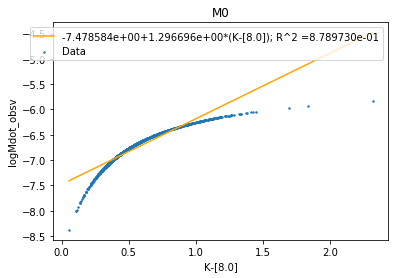


 Fit: logMdot= -3.7701543362194565 *x+ -10.206621799935107


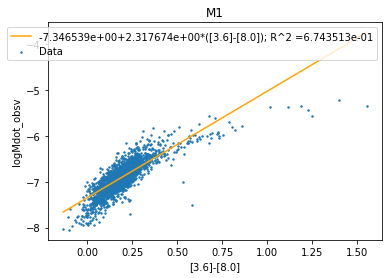

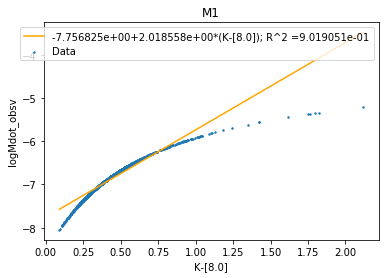


 Fit: logMdot= -2.0446885161257837 *x+ -8.734727198774648


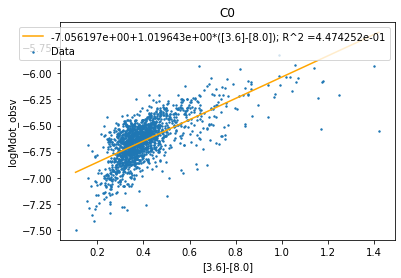

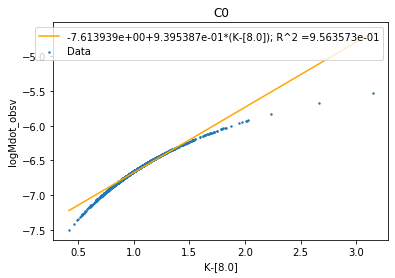


 Fit: logMdot= -4.011020742938194 *x+ -10.095639083186782


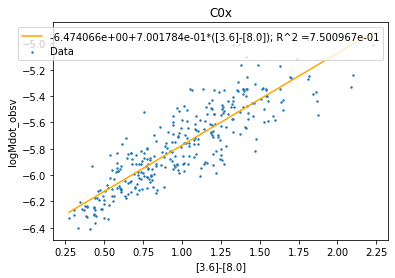

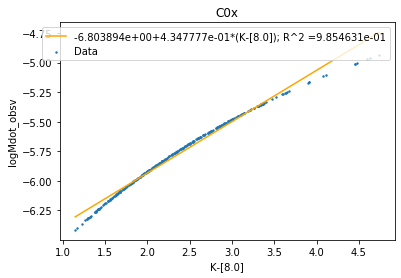


 Fit: logMdot= -2.696015682524946 *x+ -9.545507860861013


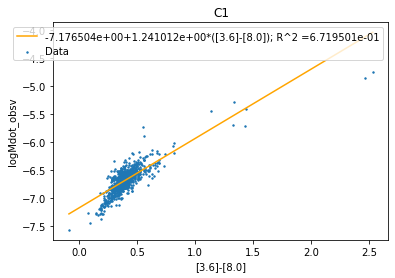

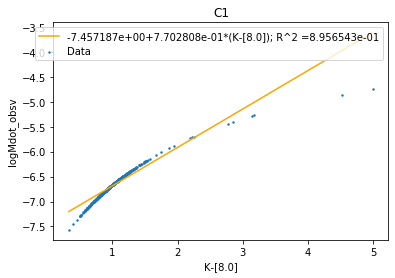

In [31]:
Directory = 'Single_Parameter_Fits/color_Mdot/log(L/R^2)'
full_parameter_analysis (M0_logLP, M0_color_Mdot, M0_reduced_for_K_minus_80, stellar_data_xlabel='log(L/R^2)', plot_label='M0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (M1_logLP, M1_color_Mdot, M1_reduced_for_K_minus_80, stellar_data_xlabel='log(L/R^2)', plot_label='M1', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0_logLP, C0_color_Mdot, C0_reduced_for_K_minus_80, stellar_data_xlabel='log(L/R^2)', plot_label='C0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0x_logLP, C0x_color_Mdot, C0x_reduced_for_K_minus_80, stellar_data_xlabel='log(L/R^2)', plot_label='C0x', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C1_logLP, C1_color_Mdot, C1_reduced_for_K_minus_80, stellar_data_xlabel='log(L/R^2)', plot_label='C1', save_fig = 1, save_folder=Directory)


 Fit: logMdot= 0.7001689544936577 *x+ -9.24033923160952


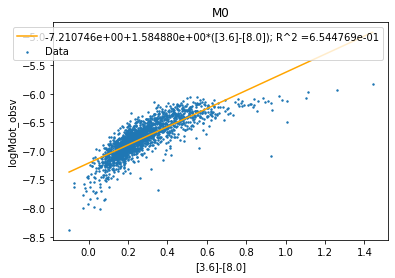

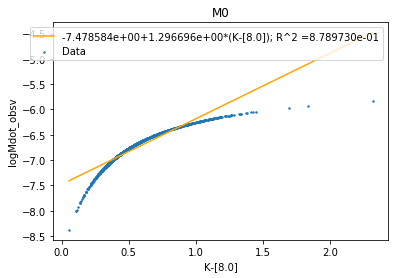


 Fit: logMdot= 1.132862004245742 *x+ -10.954676257356693


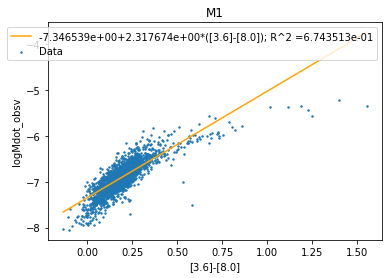

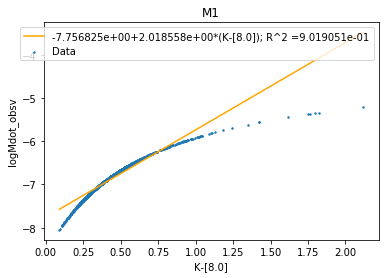


 Fit: logMdot= 0.8025461361849254 *x+ -9.551554523176828


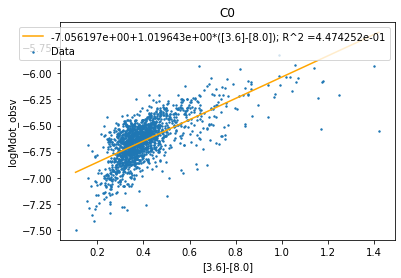

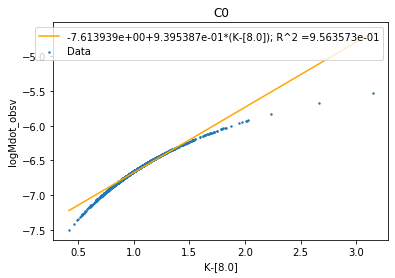


 Fit: logMdot= 1.490334231755775 *x+ -11.256641686740226


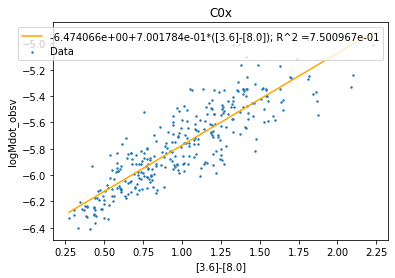

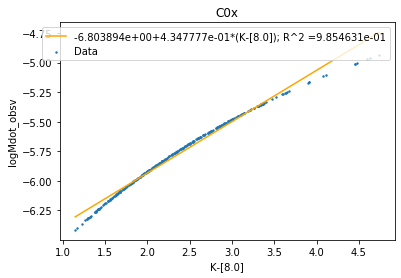


 Fit: logMdot= 1.4443923258279383 *x+ -12.023112450841749


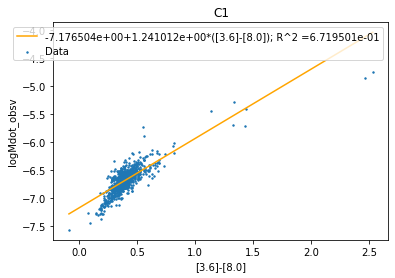

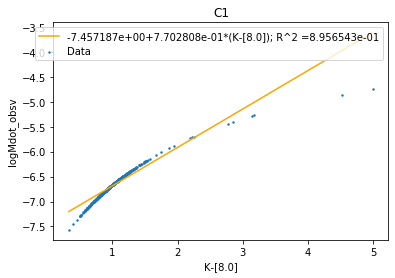

In [32]:
Directory = 'Single_Parameter_Fits/color_Mdot/log(L/M)'
full_parameter_analysis (M0_logCL, M0_color_Mdot, M0_reduced_for_K_minus_80, stellar_data_xlabel='log(L/M)', plot_label='M0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (M1_logCL, M1_color_Mdot, M1_reduced_for_K_minus_80, stellar_data_xlabel='log(L/M)', plot_label='M1', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0_logCL, C0_color_Mdot, C0_reduced_for_K_minus_80, stellar_data_xlabel='log(L/M)', plot_label='C0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0x_logCL, C0x_color_Mdot, C0x_reduced_for_K_minus_80, stellar_data_xlabel='log(L/M)', plot_label='C0x', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C1_logCL, C1_color_Mdot, C1_reduced_for_K_minus_80, stellar_data_xlabel='log(L/M)', plot_label='C1', save_fig = 1, save_folder=Directory)

Potential energy has residuals in the core mass-luminosity relation that should be removed from all star types. We need to subtract that fit from the PE fit, and redo the analysis. Temperature has residuals that should be removed in the basic parameters (M, L, P).

In [33]:
def PE_minus_resid (stellar_data_x, stellar_data_mdot, full_stellar_data, stellar_data_xlabel='', plot_label = '', save_folder = '', save_fig = 0):
    # Data Analysis: Do a chi^2 fit of our chosen parameter vs Mdot for our star, and find the residuals of that fit
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,stellar_data_mdot)
    Betas = chisqfit_returns[0]
    RSquared = chisqfit_returns[1]
    print('\n Initial Fit: logMdot=', Betas[1],'*x+',Betas[0])
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    # Data Analysis: For the input, calculate some proxies for stellar parameters (so they don't have to be fed to the function indvidually)
    logPE = calc_PE_scale(full_stellar_data)
    logg = calc_g_scale(full_stellar_data)
    logLP = calc_lum_pressure_scale(full_stellar_data)
    logCL = calc_core_lum_param(full_stellar_data)
    Correction_betas = plot_residual_vs_parameter(logMdot_residual,logCL,title=plot_label,parameter_label='log(L/M)')
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0] - (Correction_betas[0] + Correction_betas[1]*logCL)
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,logMdot_calc)
    Betas = chisqfit_returns[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    print('\n Corrected Fit: logMdot=', Betas[1],'*log(M/R)+',Correction_betas[1],'log(L/M)+',Betas[0]-Correction_betas[0])
    # First Plot: Chosen Parameter vs Mdot, so we can see what the chi^2 fit looks like
    plot.scatter(stellar_data_x,stellar_data_mdot,s=2,label = 'Data')
    fit_x = np.asarray([np.min(stellar_data_x), np.max(stellar_data_x)])
    fit_y = Betas[0] + Betas[1]*fit_x
    fit_label = str(Betas[1])[:6]+'*log(M/R)+'+str(Correction_betas[1])[:6]+'log(L/M)+'+str(Betas[0]-Correction_betas[0])[:6]+'; R^2 ='+ str(chisqfit_returns[1])[0:6]
    plot.plot(fit_x,fit_y,color='orange',label = fit_label)
    plot.xlabel(stellar_data_xlabel)
    plot.ylabel('logMdot_obsv')
    plot.title(plot_label)
    plot.legend()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_versus_' + 'log(M/R)' + '/' + plot_label
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()
    # More plots
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[PIndex]),title=plot_label,parameter_label='logP',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[LIndex]),title=plot_label,parameter_label='logL',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[MIndex]),title=plot_label,parameter_label='logM',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logPE,title=plot_label,parameter_label='log(M/R)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logg,title=plot_label,parameter_label='log(M/R^2)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logLP,title=plot_label,parameter_label='log(L/R^2)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logCL,title=plot_label,parameter_label='log(L/M)',save_folder = save_folder,save_fig = save_fig)
    # Add some plots vs color (J-[3.6] and J-K)
    color_J_minus_ThreePointSix = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[ThreePointSixIndex])
    color_ThreePointSix_minus_EightPointZero = np.asarray(full_stellar_data[ThreePointSixIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    color_J_minus_K = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[KIndex])
    color_K_minus_EightPointZero = np.asarray(full_stellar_data[KIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    plot_logmdot_vs_parameter (stellar_data_mdot,color_ThreePointSix_minus_EightPointZero , title=plot_label, parameter_label='[3.6]-[8.0]')
    plot_logmdot_vs_parameter (stellar_data_mdot, color_K_minus_EightPointZero, title=plot_label, parameter_label='K-[8.0]')
    plot_residual_vs_parameter(logMdot_residual,color_ThreePointSix_minus_EightPointZero,title=plot_label,parameter_label='[3.6]-[8.0]',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,color_K_minus_EightPointZero,title=plot_label,parameter_label='K-[8.0]',save_folder = save_folder,save_fig = save_fig)
    
    print('\n')
    plot_logmdot_vs_logmdot(stellar_data_mdot, logMdot_calc, title=plot_label,save_folder = save_folder,save_fig = save_fig)


 Initial Fit: logMdot= -1.717485072478139 *x+ -10.515389112195633


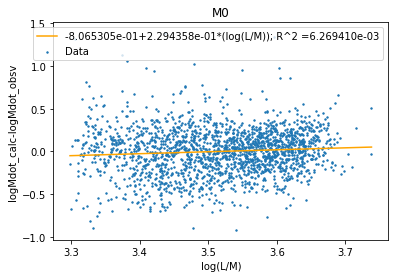


 Corrected Fit: logMdot= -1.5556228013335358 *log(M/R)+ 0.22943575230449473 log(L/M)+ -9.356731970618927


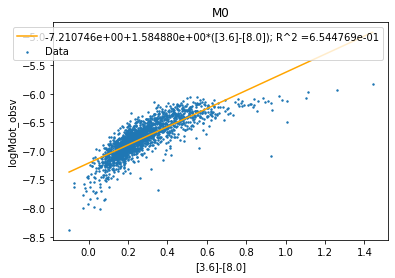

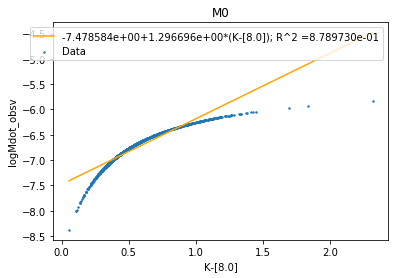




 Initial Fit: logMdot= -1.8881536584747165 *x+ -11.100508141517857


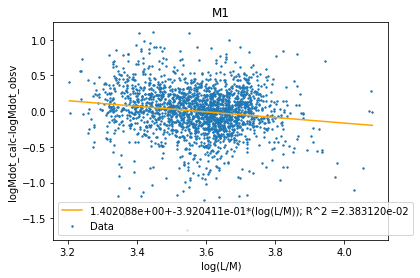


 Corrected Fit: logMdot= -2.2998742155644876 *log(M/R)+ -0.3920410533546609 log(L/M)+ -13.417853953265576


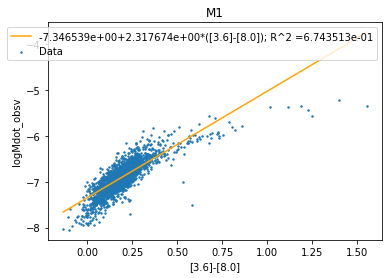

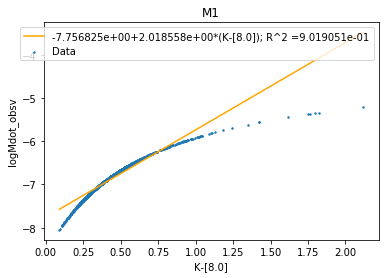




 Initial Fit: logMdot= -0.8370084245632918 *x+ -8.51049246113835


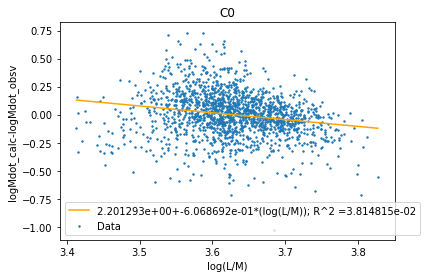


 Corrected Fit: logMdot= -0.9891859776037477 *log(M/R)+ -0.6068692223896286 log(L/M)+ -11.05177465402782


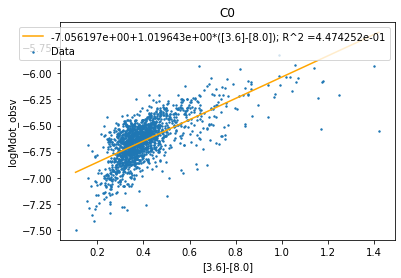

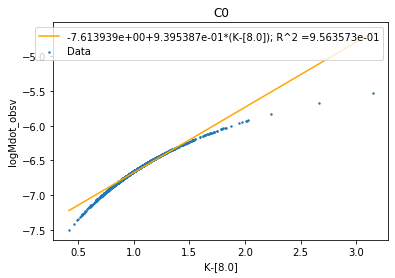




 Initial Fit: logMdot= -0.9573254283521415 *x+ -8.01360806394284


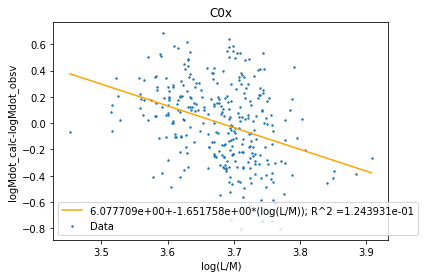


 Corrected Fit: logMdot= -0.5780582696582215 *log(M/R)+ -1.651757674996655 log(L/M)+ -13.203605974625834


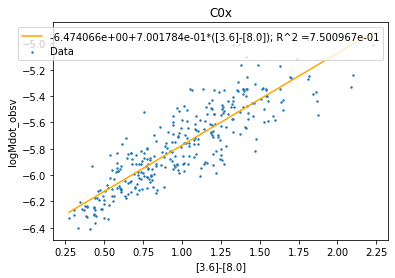

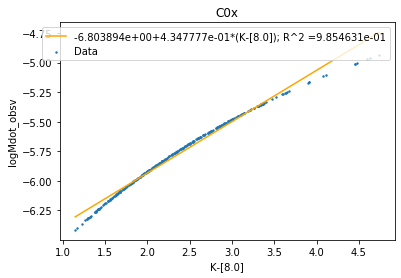




 Initial Fit: logMdot= -1.3037528136377263 *x+ -9.675037803862274


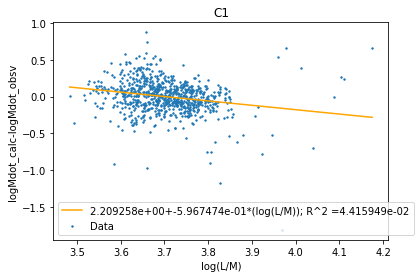


 Corrected Fit: logMdot= -1.6521705941913318 *log(M/R)+ -0.5967473755097746 log(L/M)+ -12.685837327916262


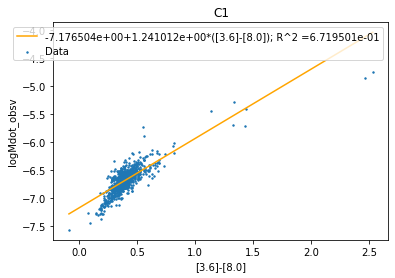

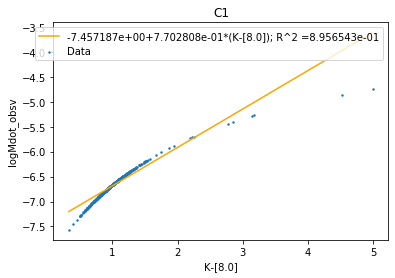

In [34]:
Directory = 'Single_Parameter_Fits/color_Mdot/ExtendedAnalyses/log(MdivR)'
PE_minus_resid (M0_logPE, M0_color_Mdot, M0_reduced_for_K_minus_80, stellar_data_xlabel='log(M/R)', plot_label='M0', save_fig = 1, save_folder=Directory)
PE_minus_resid (M1_logPE, M1_color_Mdot, M1_reduced_for_K_minus_80, stellar_data_xlabel='log(M/R)', plot_label='M1', save_fig = 1, save_folder=Directory)
PE_minus_resid (C0_logPE, C0_color_Mdot, C0_reduced_for_K_minus_80, stellar_data_xlabel='log(M/R)', plot_label='C0', save_fig = 1, save_folder=Directory)
PE_minus_resid (C0x_logPE, C0x_color_Mdot, C0x_reduced_for_K_minus_80, stellar_data_xlabel='log(M/R)', plot_label='C0x', save_fig = 1, save_folder=Directory)
PE_minus_resid (C1_logPE, C1_color_Mdot, C1_reduced_for_K_minus_80, stellar_data_xlabel='log(M/R)', plot_label='C1', save_fig = 1, save_folder=Directory)

In [35]:
def T_minus_resid (stellar_data_x, stellar_data_mdot, full_stellar_data, fed_index, stellar_data_xlabel='', plot_label = '', save_folder = '', save_fig = 0):
    # Data Analysis: Do a chi^2 fit of our chosen parameter vs Mdot for our star, and find the residuals of that fit
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,stellar_data_mdot)
    Betas = chisqfit_returns[0]
    print('\n Initial Fit: logMdot=', Betas[1],'*x+',Betas[0])
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    # Data Analysis: For the input, calculate some proxies for stellar parameters (so they don't have to be fed to the function indvidually)
    logPE = calc_PE_scale(full_stellar_data)
    logg = calc_g_scale(full_stellar_data)
    logLP = calc_lum_pressure_scale(full_stellar_data)
    logCL = calc_core_lum_param(full_stellar_data)
    if fed_index == RIndex:
        Correction_betas = plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[fed_index]),title=plot_label,parameter_label='log(R)')
    elif fed_index == LIndex:
        Correction_betas = plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[fed_index]),title=plot_label,parameter_label='log(L)')
    elif fed_index == PIndex:
        Correction_betas = plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[fed_index]),title=plot_label,parameter_label='log(P)')
    elif fed_index == MIndex:
        Correction_betas = plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[fed_index]),title=plot_label,parameter_label='log(M)')
    
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0] - (Correction_betas[0] + Correction_betas[1]*np.log10(full_stellar_data[fed_index]))
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,logMdot_calc)
    Betas = chisqfit_returns[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    if fed_index == RIndex:
        print('\n Corrected Fit: logMdot=', Betas[1],'*log(L/R^2)+',Correction_betas[1],'log(R)+',Betas[0]-Correction_betas[0])
        fit_label = str(Betas[1])[:6]+'*log(L/R^2)+'+str(Correction_betas[1])[:6]+'log(R)+'+str(Betas[0]-Correction_betas[0])[:6]
    elif fed_index == LIndex:
        print('\n Corrected Fit: logMdot=', Betas[1],'*log(L/R^2)+',Correction_betas[1],'log(L)+',Betas[0]-Correction_betas[0])
        fit_label = str(Betas[1])[:6]+'*log(L/R^2)+'+str(Correction_betas[1])[:6]+'log(L)+'+str(Betas[0]-Correction_betas[0])[:6]
    elif fed_index == PIndex:
        print('\n Corrected Fit: logMdot=', Betas[1],'*log(L/R^2)+',Correction_betas[1],'log(P)+',Betas[0]-Correction_betas[0])
        fit_label = str(Betas[1])[:6]+'*log(L/R^2)+'+str(Correction_betas[1])[:6]+'log(P)+'+str(Betas[0]-Correction_betas[0])[:6]
    elif fed_index == MIndex:
        print('\n Corrected Fit: logMdot=', Betas[1],'*log(L/R^2)+',Correction_betas[1],'log(M)+',Betas[0]-Correction_betas[0])
        fit_label = str(Betas[1])[:6]+'*log(L/R^2)+'+str(Correction_betas[1])[:6]+'log(M)+'+str(Betas[0]-Correction_betas[0])[:6]
    # First Plot: Chosen Parameter vs Mdot, so we can see what the chi^2 fit looks like
    plot.scatter(stellar_data_x,stellar_data_mdot,s=2,label='Data')
    fit_x = np.asarray([np.min(stellar_data_x), np.max(stellar_data_x)])
    fit_y = Betas[0] + Betas[1]*fit_x
    plot.plot(fit_x,fit_y,color='orange',label=fit_label)
    plot.xlabel(stellar_data_xlabel)
    plot.ylabel('logMdot_obsv')
    plot.title(plot_label)
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_versus_' + 'log(L/R^2)' + '/' + plot_label
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()
    # More plots
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[PIndex]),title=plot_label,parameter_label='logP', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[LIndex]),title=plot_label,parameter_label='logL', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[MIndex]),title=plot_label,parameter_label='logM', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,logPE,title=plot_label,parameter_label='log(M/R)', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,logg,title=plot_label,parameter_label='log(M/R^2)', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,logLP,title=plot_label,parameter_label='log(L/R^2)', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,logCL,title=plot_label,parameter_label='log(L/M)', save_fig = 1, save_folder=Directory)
    # Add some plots vs color (J-[3.6] and J-K)
    color_J_minus_ThreePointSix = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[ThreePointSixIndex])
    color_ThreePointSix_minus_EightPointZero = np.asarray(full_stellar_data[ThreePointSixIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    color_J_minus_K = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[KIndex])
    color_K_minus_EightPointZero = np.asarray(full_stellar_data[KIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    plot_logmdot_vs_parameter (stellar_data_mdot,color_ThreePointSix_minus_EightPointZero , title=plot_label, parameter_label='[3.6]-[8.0]')
    plot_logmdot_vs_parameter (stellar_data_mdot, color_K_minus_EightPointZero, title=plot_label, parameter_label='K-[8.0]')
    plot_residual_vs_parameter(logMdot_residual,color_ThreePointSix_minus_EightPointZero,title=plot_label,parameter_label='[3.6]-[8.0]',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,color_K_minus_EightPointZero,title=plot_label,parameter_label='K-[8.0]',save_folder = save_folder,save_fig = save_fig)
    
    #print('\n')
    plot_logmdot_vs_logmdot(stellar_data_mdot, logMdot_calc, title=plot_label, save_fig = 1, save_folder=Directory)


 Initial Fit: logMdot= -3.1370744003480695 *x+ -9.440317853985007


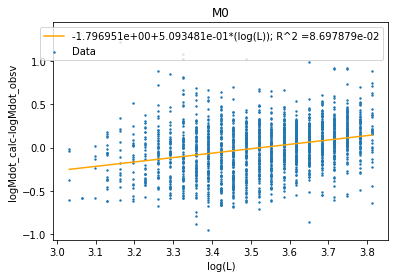


 Corrected Fit: logMdot= -2.23642045186149 *log(L/R^2)+ 0.5093481425192288 log(L)+ -6.879317055427291


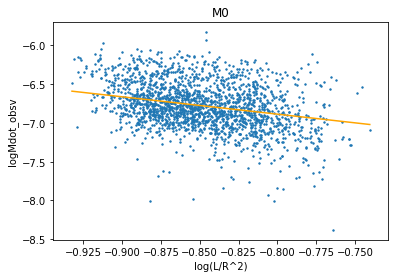

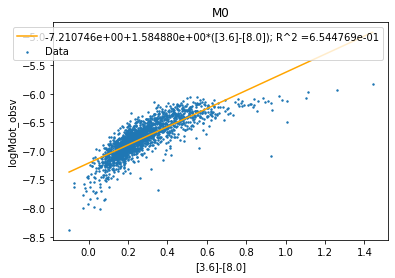

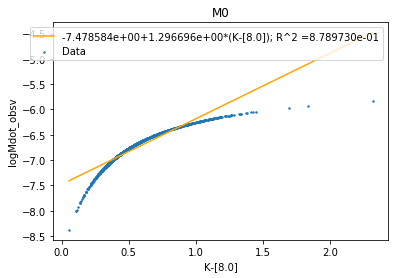

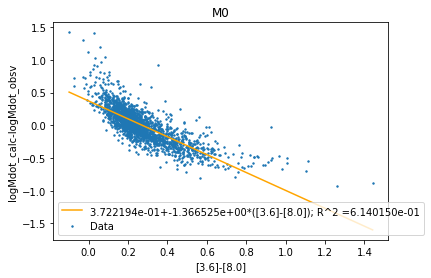

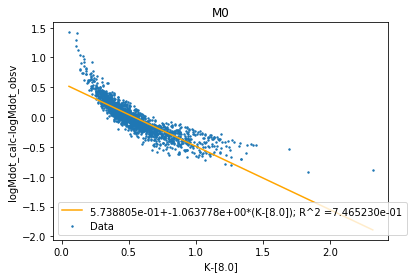


 Initial Fit: logMdot= -3.7701543362194565 *x+ -10.206621799935107


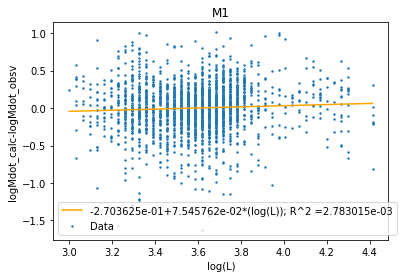


 Corrected Fit: logMdot= -3.4970136919058237 *log(L/R^2)+ 0.07545762134611472 log(L)+ -9.696927515843386


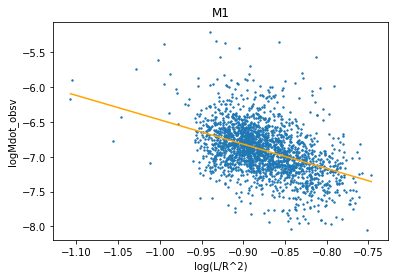

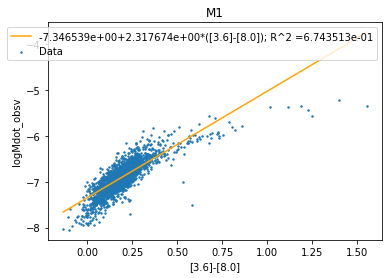

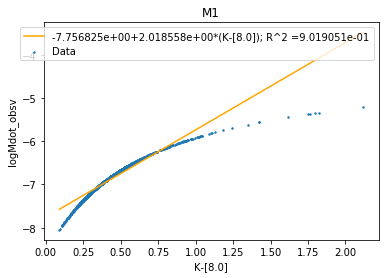

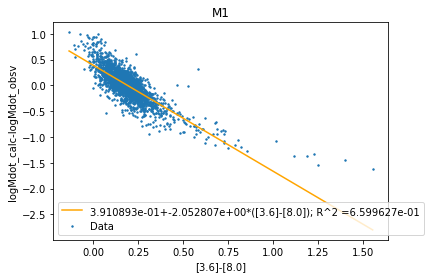

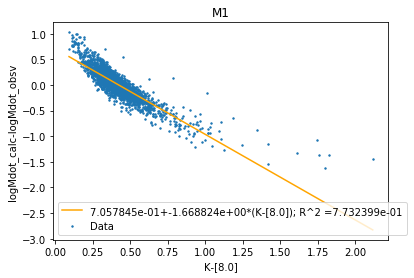


 Initial Fit: logMdot= -2.0446885161257837 *x+ -8.734727198774648


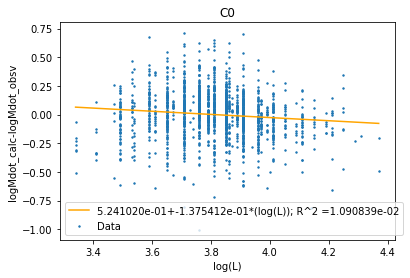


 Corrected Fit: logMdot= -1.973507172615087 *log(L/R^2)+ -0.13754121556906176 log(L)+ -9.185922739137197


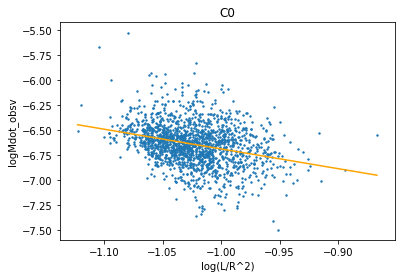

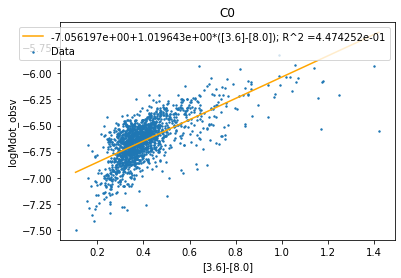

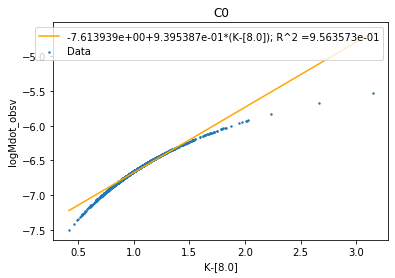

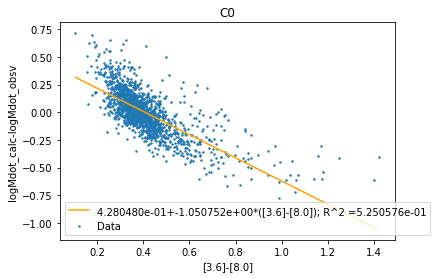

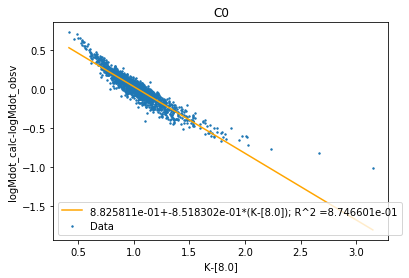


 Initial Fit: logMdot= -4.011020742938194 *x+ -10.095639083186782


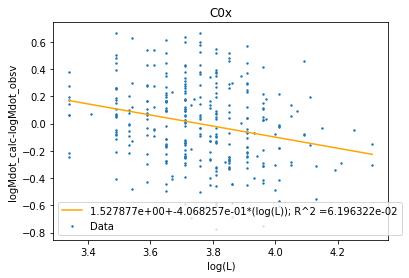


 Corrected Fit: logMdot= -3.2568838867565537 *log(L/R^2)+ -0.40682570107551513 log(L)+ -10.810770896851793


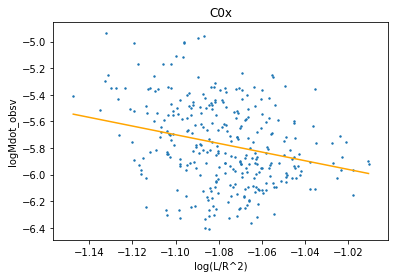

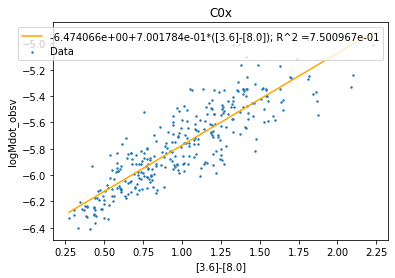

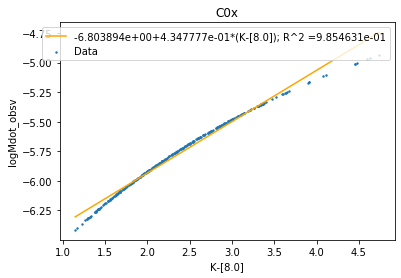

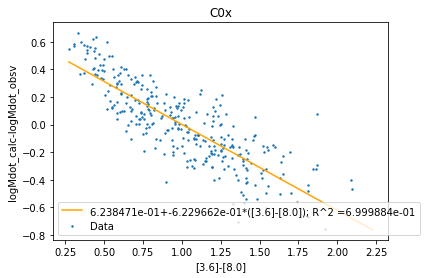

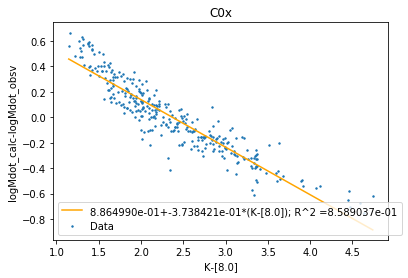


 Initial Fit: logMdot= -2.696015682524946 *x+ -9.545507860861013


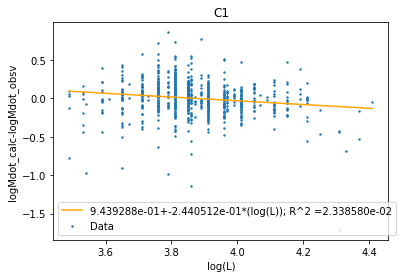


 Corrected Fit: logMdot= -2.724383692582437 *log(L/R^2)+ -0.24405122619544106 log(L)+ -10.519633062179453


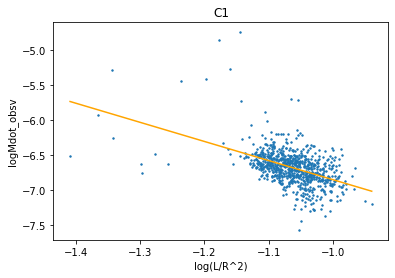

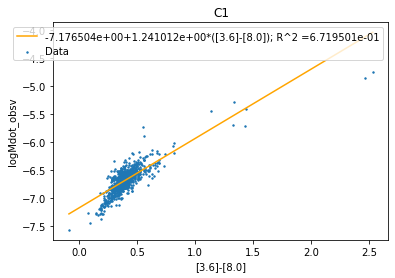

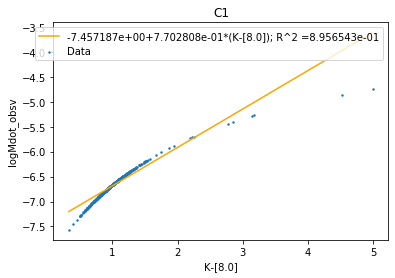

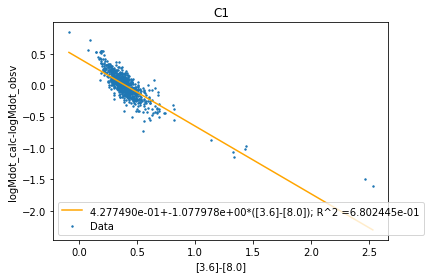

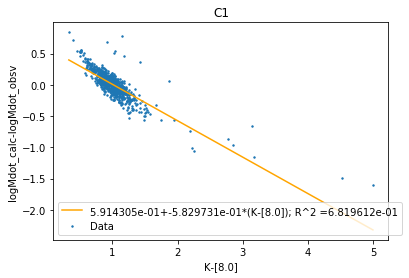

In [36]:
Directory = 'Single_Parameter_Fits/color_Mdot/ExtendedAnalyses/log(LdivR^2)/subtract_logL'
T_minus_resid (M0_logLP, M0_color_Mdot, M0_reduced_for_K_minus_80, LIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M0')
T_minus_resid (M1_logLP, M1_color_Mdot, M1_reduced_for_K_minus_80, LIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M1')
T_minus_resid (C0_logLP, C0_color_Mdot, C0_reduced_for_K_minus_80, LIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0')
T_minus_resid (C0x_logLP, C0x_color_Mdot, C0x_reduced_for_K_minus_80, LIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0x')
T_minus_resid (C1_logLP, C1_color_Mdot, C1_reduced_for_K_minus_80, LIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C1')


 Initial Fit: logMdot= -3.1370744003480695 *x+ -9.440317853985007


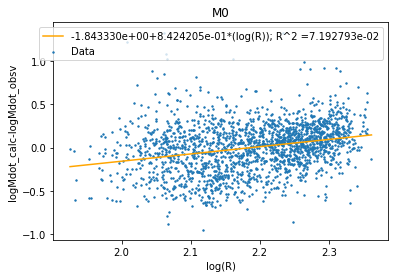


 Corrected Fit: logMdot= -1.9710598844080156 *log(L/R^2)+ 0.8424204923283056 log(R)+ -6.6078254212896965


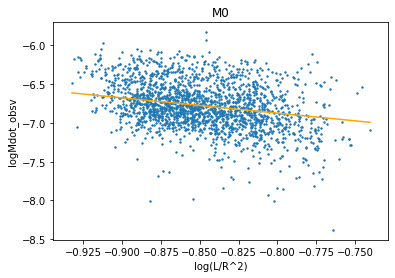

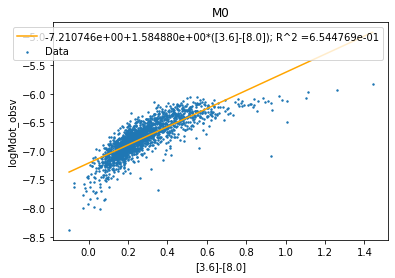

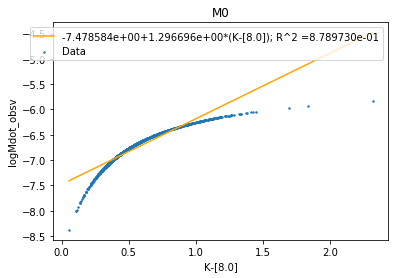

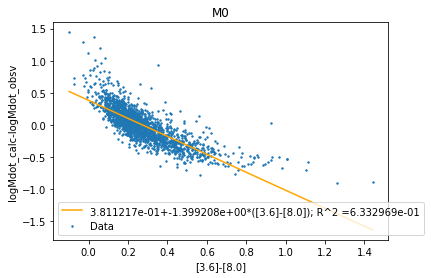

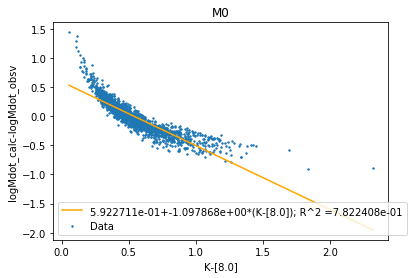


 Initial Fit: logMdot= -3.7701543362194565 *x+ -10.206621799935107


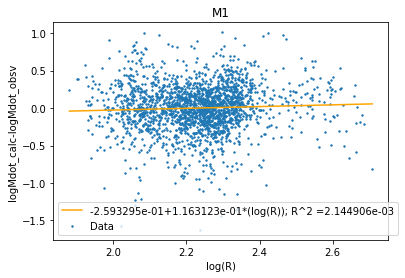


 Corrected Fit: logMdot= -3.5014851649550085 *log(L/R^2)+ 0.11631232045448434 log(R)+ -9.711878447319727


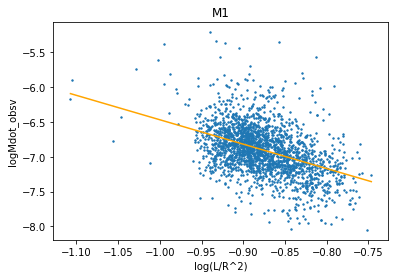

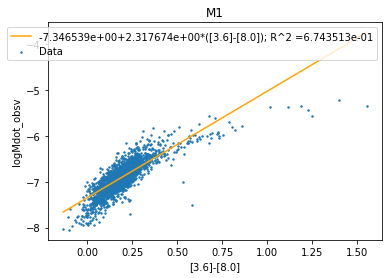

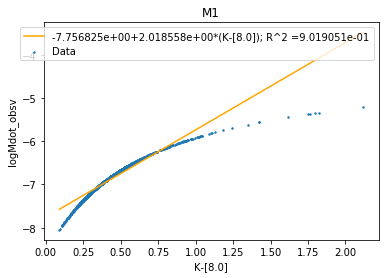

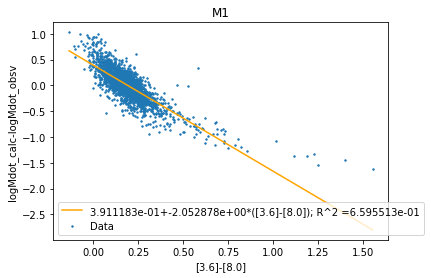

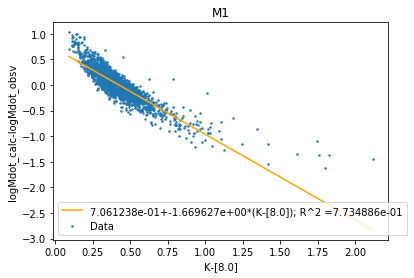


 Initial Fit: logMdot= -2.0446885161257837 *x+ -8.734727198774648


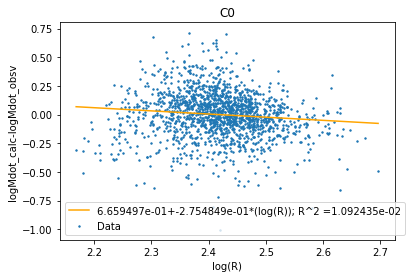


 Corrected Fit: logMdot= -2.1111454801241387 *log(L/R^2)+ -0.27548490760572203 log(R)+ -9.468744498939442


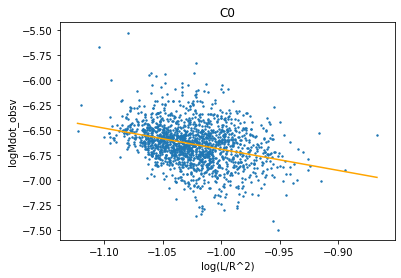

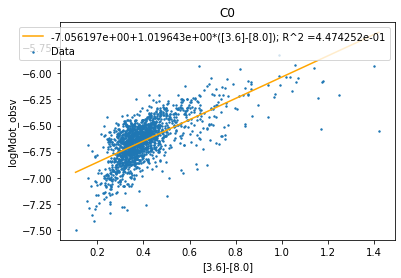

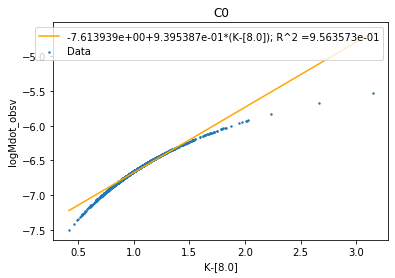

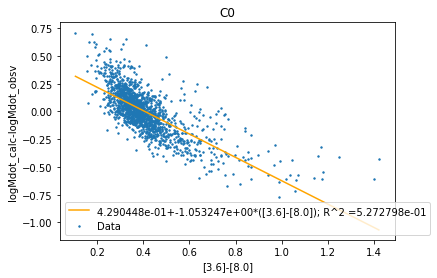

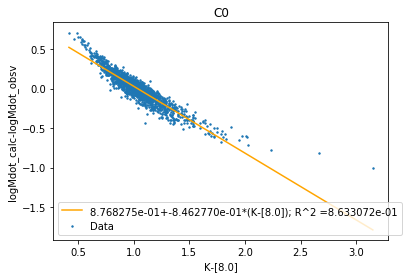


 Initial Fit: logMdot= -4.011020742938194 *x+ -10.095639083186782


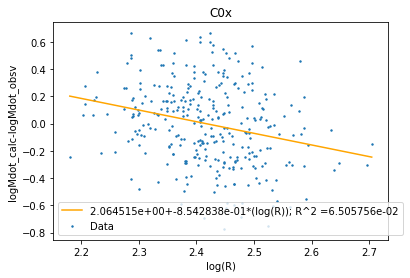


 Corrected Fit: logMdot= -3.6463654420057052 *log(L/R^2)+ -0.854283810189928 log(R)+ -11.767158904148236


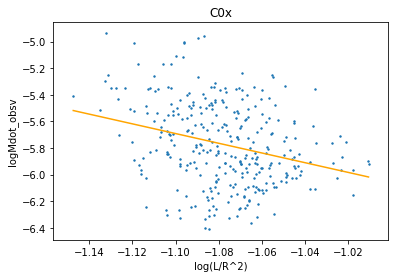

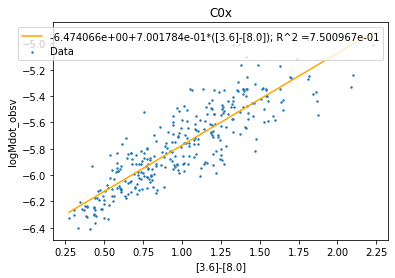

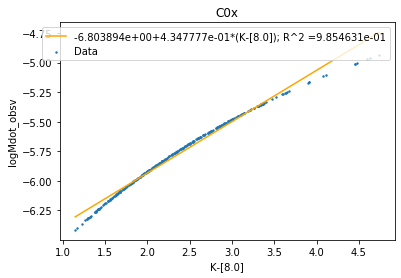

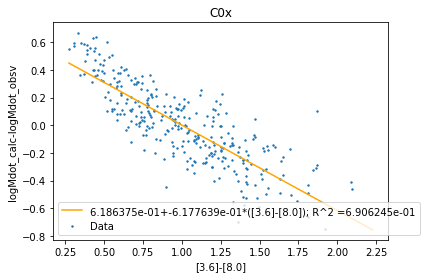

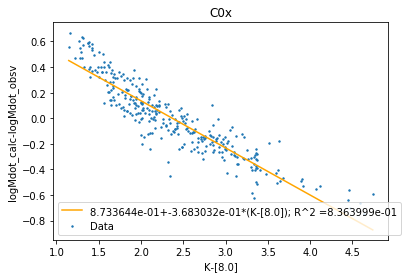


 Initial Fit: logMdot= -2.696015682524946 *x+ -9.545507860861013


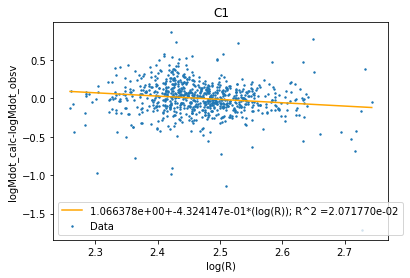


 Corrected Fit: logMdot= -2.9373545274045396 *log(L/R^2)+ -0.4324146989881933 log(R)+ -10.868779078312302


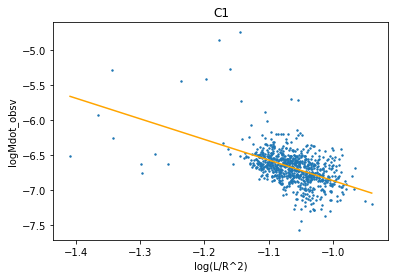

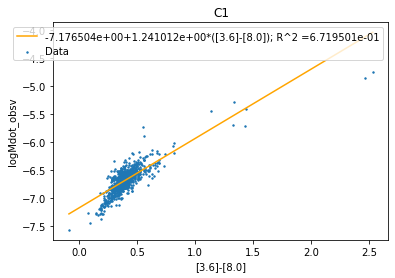

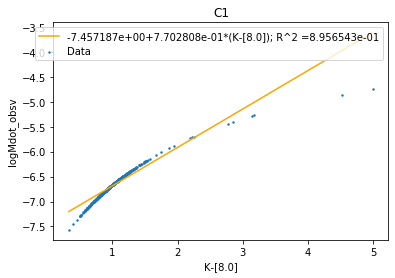

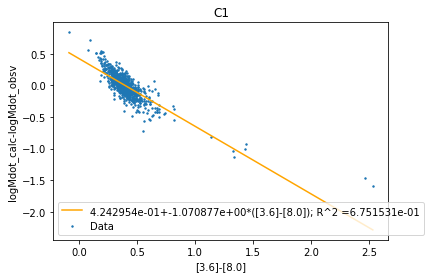

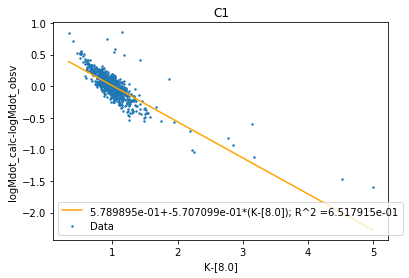

In [37]:
Directory = 'Single_Parameter_Fits/color_Mdot/ExtendedAnalyses/log(LdivR^2)/subtract_logR'
T_minus_resid (M0_logLP, M0_color_Mdot, M0_reduced_for_K_minus_80, RIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M0')
T_minus_resid (M1_logLP, M1_color_Mdot, M1_reduced_for_K_minus_80, RIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M1')
T_minus_resid (C0_logLP, C0_color_Mdot, C0_reduced_for_K_minus_80, RIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0')
T_minus_resid (C0x_logLP, C0x_color_Mdot, C0x_reduced_for_K_minus_80, RIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0x')
T_minus_resid (C1_logLP, C1_color_Mdot, C1_reduced_for_K_minus_80, RIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C1')


 Initial Fit: logMdot= -3.1370744003480695 *x+ -9.440317853985007


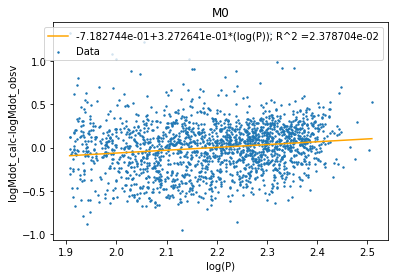


 Corrected Fit: logMdot= -2.051624040849583 *log(L/R^2)+ 0.32726407606368585 log(P)+ -7.801225816511479


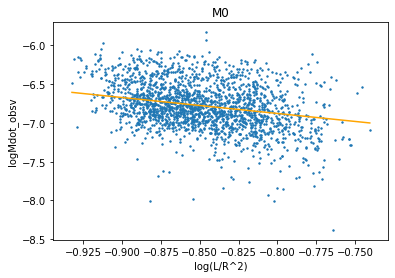

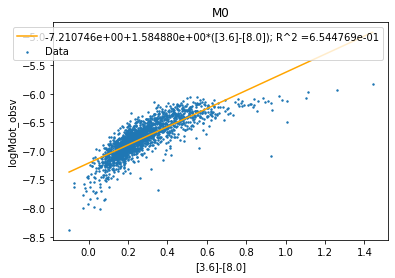

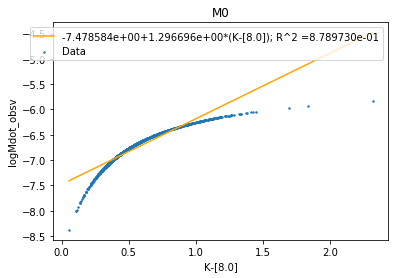

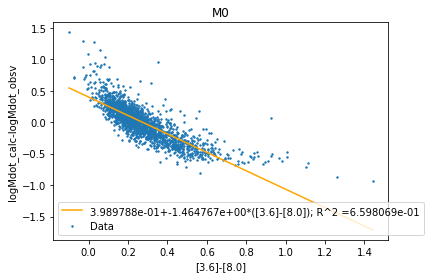

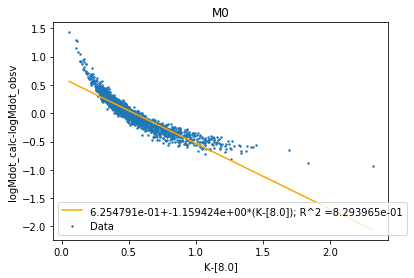


 Initial Fit: logMdot= -3.7701543362194565 *x+ -10.206621799935107


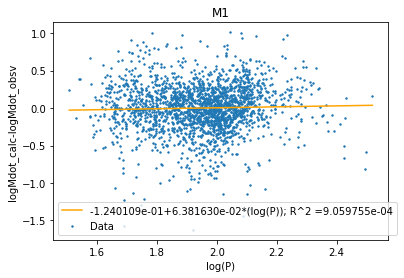


 Corrected Fit: logMdot= -3.5639244413543865 *log(L/R^2)+ 0.06381630290632101 log(P)+ -9.901907779464647


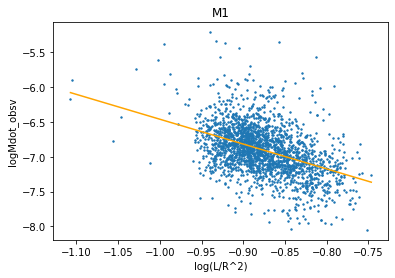

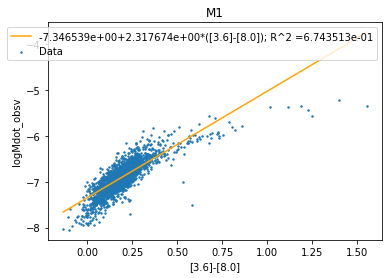

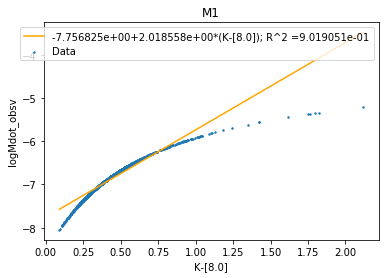

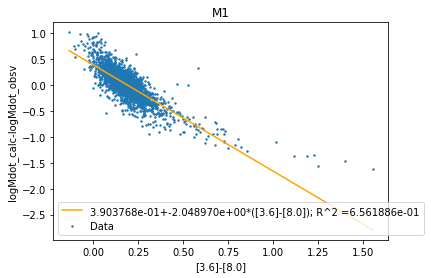

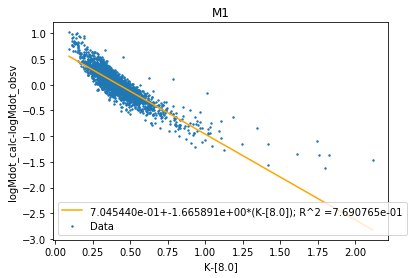


 Initial Fit: logMdot= -2.0446885161257837 *x+ -8.734727198774648


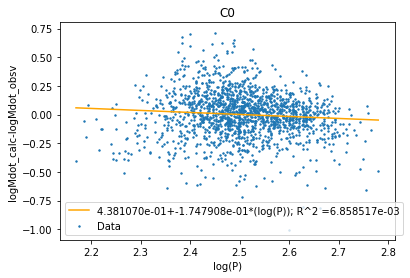


 Corrected Fit: logMdot= -2.373257535545519 *log(L/R^2)+ -0.17479077844291246 log(P)+ -9.509366518546551


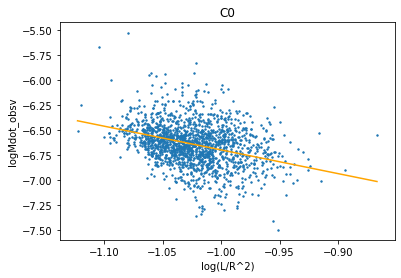

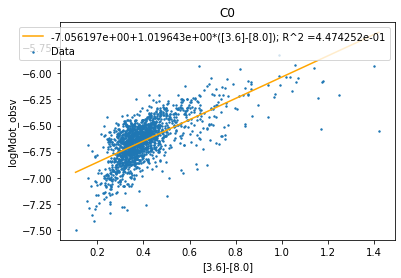

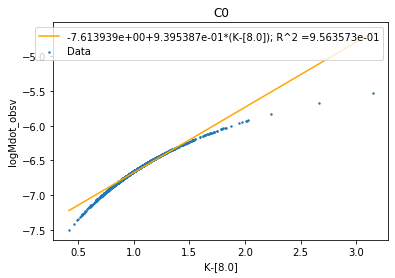

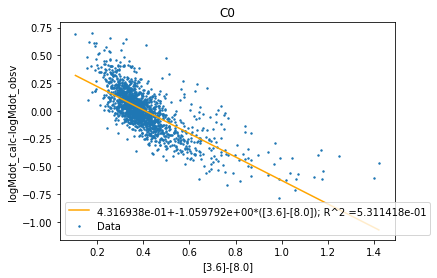

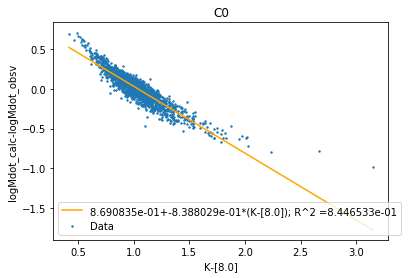


 Initial Fit: logMdot= -4.011020742938194 *x+ -10.095639083186782


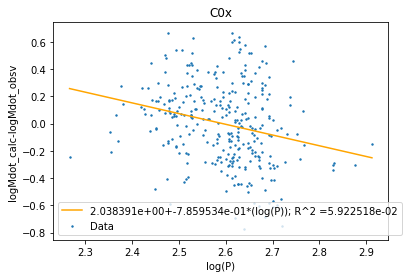


 Corrected Fit: logMdot= -4.968870736107651 *log(L/R^2)+ -0.7859533657057579 log(P)+ -13.166320681342842


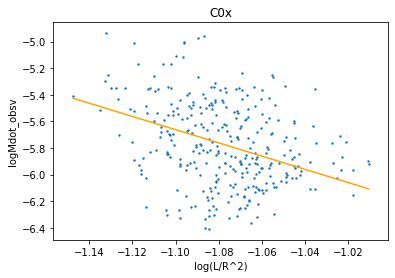

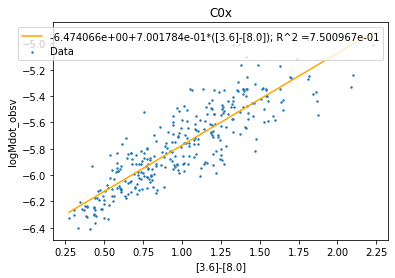

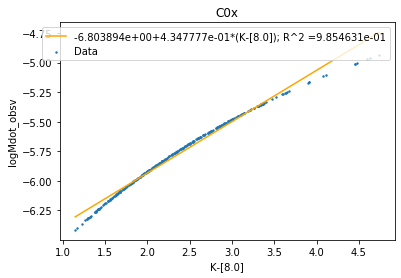

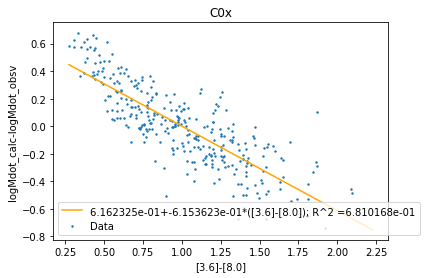

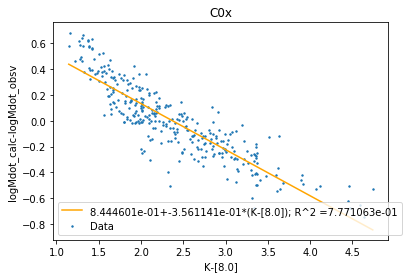


 Initial Fit: logMdot= -2.696015682524946 *x+ -9.545507860861013


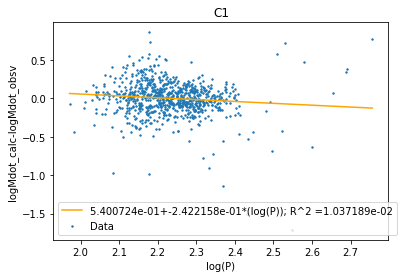


 Corrected Fit: logMdot= -3.071304319931748 *log(L/R^2)+ -0.24221578158551726 log(P)+ -10.48505661222992


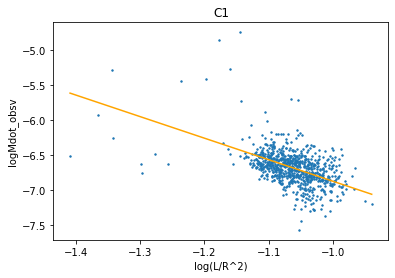

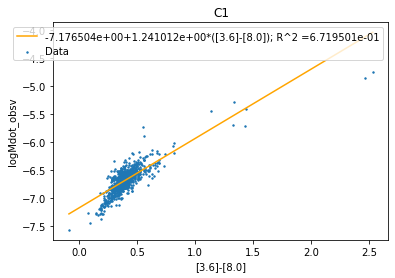

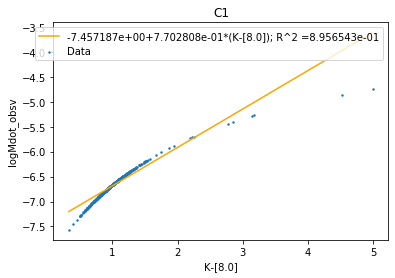

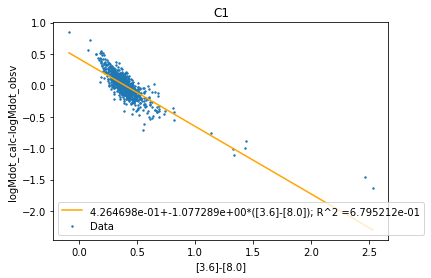

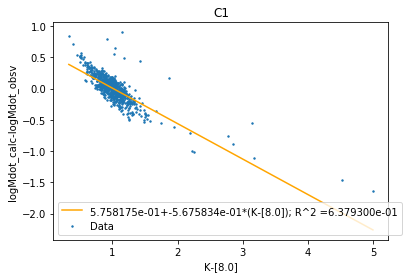

In [38]:
Directory = 'Single_Parameter_Fits/color_Mdot/ExtendedAnalyses/log(LdivR^2)/subtract_logP'
T_minus_resid (M0_logLP, M0_color_Mdot, M0_reduced_for_K_minus_80, PIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M0')
T_minus_resid (M1_logLP, M1_color_Mdot, M1_reduced_for_K_minus_80, PIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M1')
T_minus_resid (C0_logLP, C0_color_Mdot, C0_reduced_for_K_minus_80, PIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0')
T_minus_resid (C0x_logLP, C0x_color_Mdot, C0x_reduced_for_K_minus_80, PIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0x')
T_minus_resid (C1_logLP, C1_color_Mdot, C1_reduced_for_K_minus_80, PIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C1')


 Initial Fit: logMdot= -3.1370744003480695 *x+ -9.440317853985007


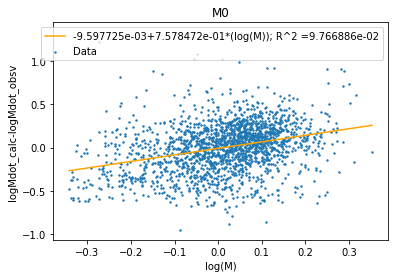


 Corrected Fit: logMdot= -3.6336477927416673 *log(L/R^2)+ 0.7578471781286574 log(M)+ -9.851977122694516


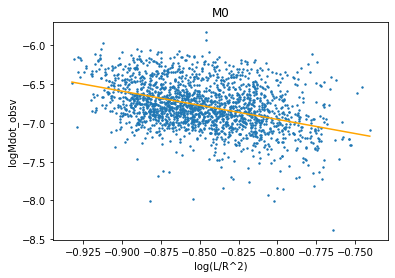

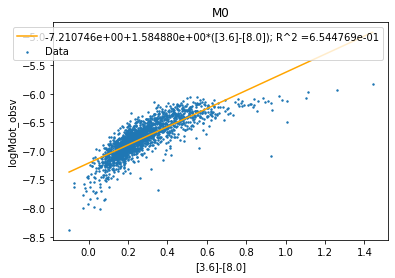

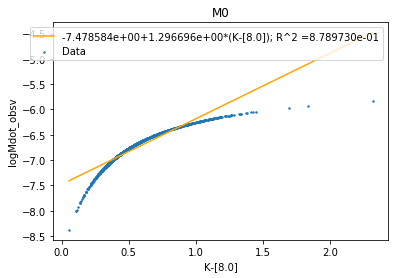

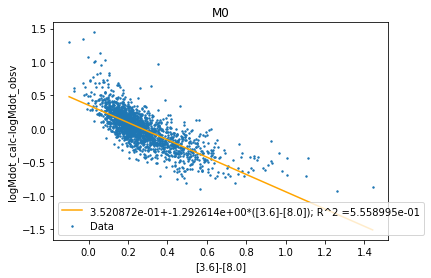

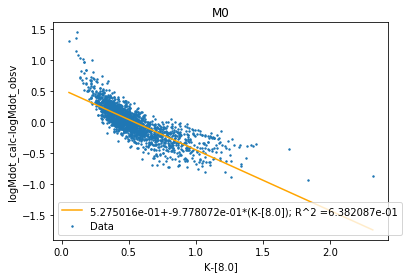


 Initial Fit: logMdot= -3.7701543362194565 *x+ -10.206621799935107


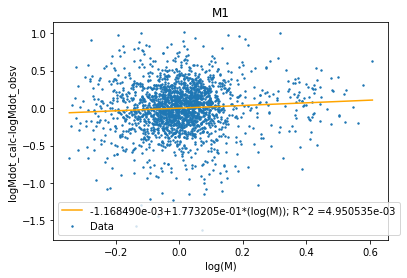


 Corrected Fit: logMdot= -3.6375101631055684 *log(L/R^2)+ 0.17732052567256681 log(M)+ -10.089227576524847


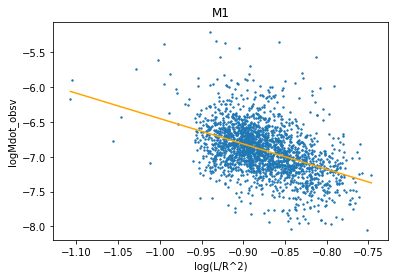

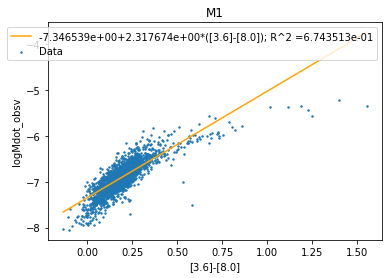

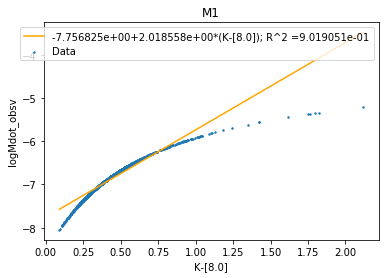

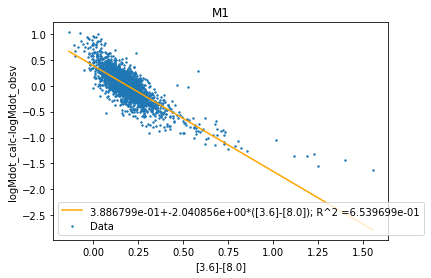

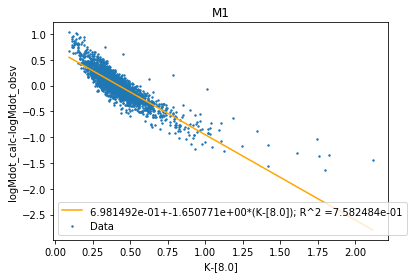


 Initial Fit: logMdot= -2.0446885161257837 *x+ -8.734727198774648


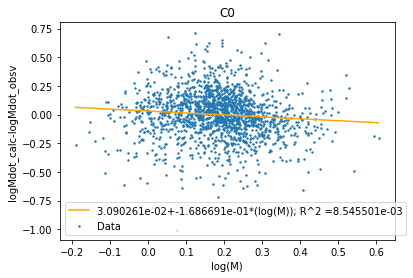


 Corrected Fit: logMdot= -1.761609077841544 *log(L/R^2)+ -0.16866907441819046 log(M)+ -8.475689604904366


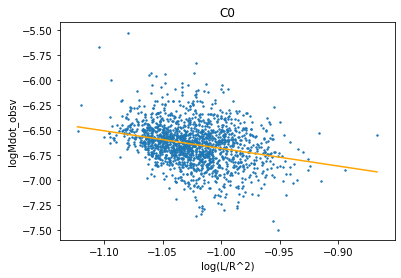

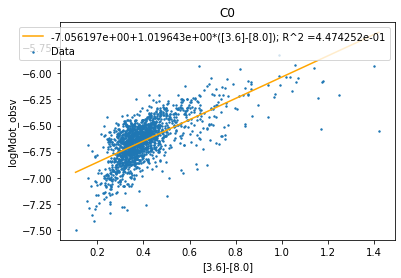

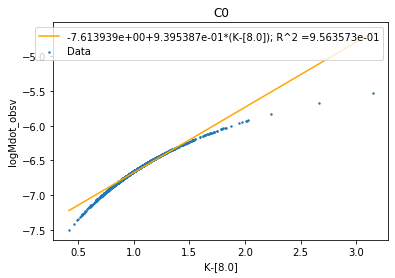

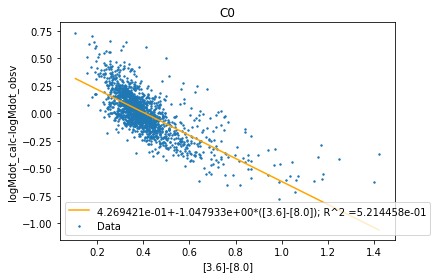

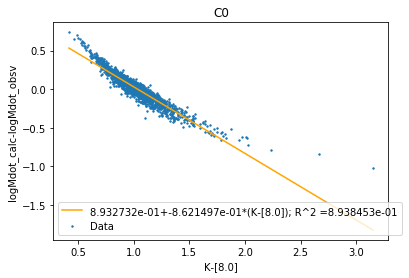


 Initial Fit: logMdot= -4.011020742938194 *x+ -10.095639083186782


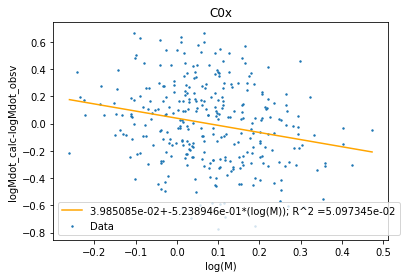


 Corrected Fit: logMdot= -2.6845798573679707 *log(L/R^2)+ -0.5238946433212824 log(M)+ -8.705963095465904


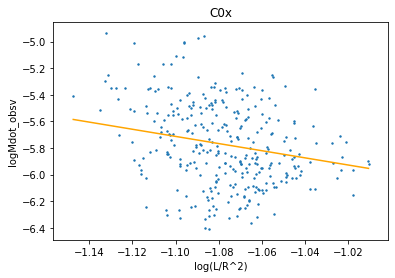

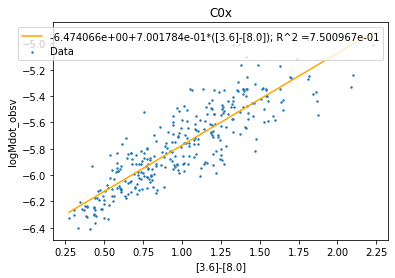

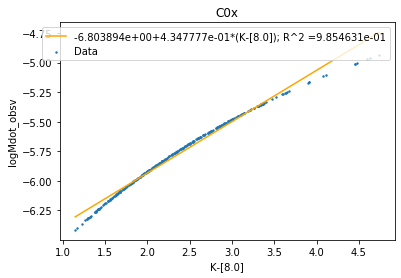

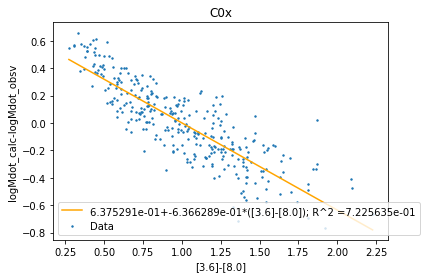

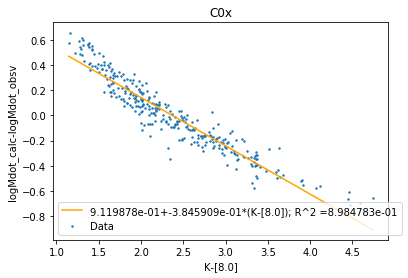


 Initial Fit: logMdot= -2.696015682524946 *x+ -9.545507860861013


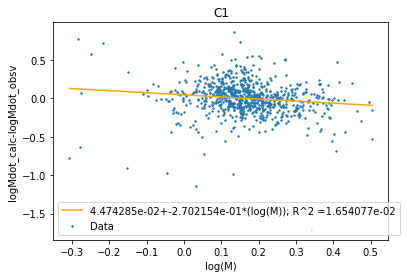


 Corrected Fit: logMdot= -2.3519087222611206 *log(L/R^2)+ -0.2702153608597377 log(M)+ -9.22396571626959


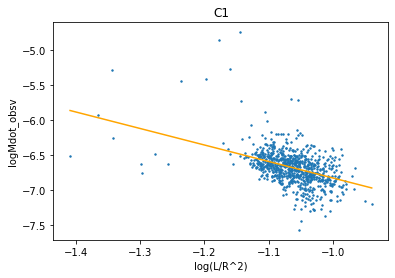

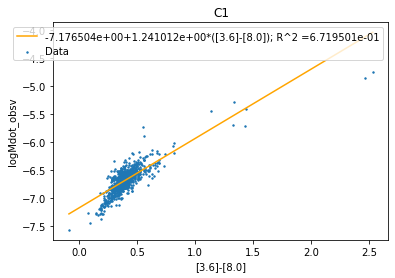

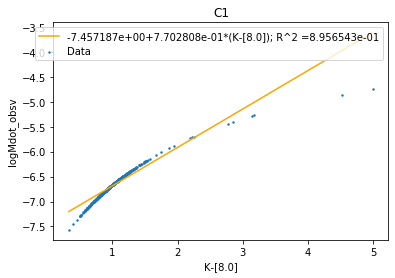

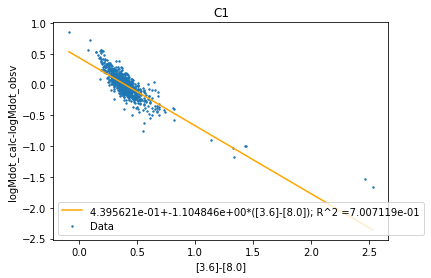

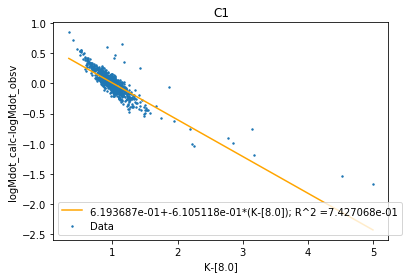

In [39]:
Directory = 'Single_Parameter_Fits/color_Mdot/ExtendedAnalyses/log(LdivR^2)/subtract_logM'
T_minus_resid (M0_logLP, M0_color_Mdot, M0_reduced_for_K_minus_80, MIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M0')
T_minus_resid (M1_logLP, M1_color_Mdot, M1_reduced_for_K_minus_80, MIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M1')
T_minus_resid (C0_logLP, C0_color_Mdot, C0_reduced_for_K_minus_80, MIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0')
T_minus_resid (C0x_logLP, C0x_color_Mdot, C0x_reduced_for_K_minus_80, MIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0x')
T_minus_resid (C1_logLP, C1_color_Mdot, C1_reduced_for_K_minus_80, MIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C1')

Removing residuals in from our Temperature proxy results in no significant improvement. We should take the initial fit to be complete.